# Hafta 13 · Dikkat Mekanizması ve Transformer

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde önce ölçekli nokta çarpım dikkatini NumPy ile elle yazacak, √dₖ ve konum kodlaması deneylerini yapacak, PyTorch'un hazır Transformer katmanlarını ve BERT, GPT-2, T5, ViT, Swin, CLIP'in parametre sayılarını inceleyeceksiniz. Defterin ikinci yarısı bir **proje**: ders notlarımızın metniyle karakter düzeyinde, **sıfırdan bir mini GPT** yazıp eğitecek ve ona metin ürettireceksiniz. Proje CPU'da birkaç dakikada çalışır; GPU gerekmez.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Ölçekli nokta çarpım dikkati (Çözümlü Örnek 13.1)
Dikkat(Q, K, V) = softmax(QKᵀ / √dₖ) V

In [2]:
import numpy as np

def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))  # sayısal kararlılık
    return e / e.sum(axis=-1, keepdims=True)

def dikkat(Q, K, V, maske=None):
    skor = Q @ K.T / np.sqrt(Q.shape[-1])   # ölçekli skorlar (n x n)
    if maske is not None:
        skor = np.where(maske, -1e9, skor)  # geleceği gizle
    A = softmax(skor)                       # dikkat ağırlıkları
    return A @ V, A

# Çözümlü Örnek 13.1
Q = K = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)
V = np.array([[2, 0], [0, 2], [1, 1]], dtype=float)
cikti, A = dikkat(Q, K, V)
print(A.round(3), cikti.round(3), sep="\n")

[[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]]
[[1.203 0.797]
 [0.797 1.203]
 [1.    1.   ]]


## 2. Deney: √dₖ ile bölmezsek ne olur?
Rastgele sorgu ve anahtarlarla nokta çarpım skorlarının ölçeğini ve softmax'ın en büyük ağırlığını boyuta göre inceleyelim.

d=  2  skor std= 1.4
d=  8  skor std= 2.8
d= 32  skor std= 5.7
d=128  skor std=11.3
d=512  skor std=22.7


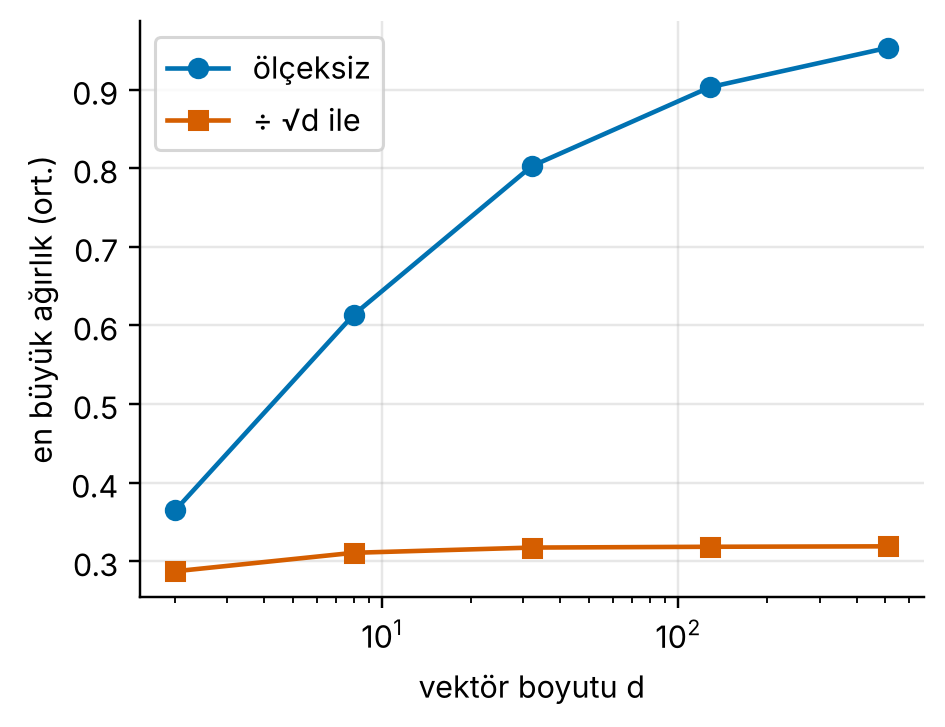

In [3]:
rng = np.random.default_rng(0)
D = [2, 8, 32, 128, 512]; ham, olc = [], []
for d in D:
    q = rng.standard_normal((1000, d))      # 1000 sorgu
    k = rng.standard_normal((1000, 10, d))  # 10'ar anahtar
    s = np.einsum("nd,nkd->nk", q, k)       # skorlar
    ham.append(softmax(s).max(1).mean())
    olc.append(softmax(s / np.sqrt(d)).max(1).mean())
    print(f"d={d:3d}  skor std={s.std():4.1f}")
plt.figure(figsize=(4.6, 3.4))
plt.semilogx(D, ham, "o-", label="ölçeksiz")
plt.semilogx(D, olc, "s-", label="÷ √d ile")
plt.xlabel("vektör boyutu d")
plt.ylabel("en büyük ağırlık (ort.)")
plt.legend(); plt.show()

## 3. Sinüzoidal konum kodlaması (Çözümlü Örnek 13.2 ve Şekil 13.4)

[[ 0.841  0.54   0.01   1.   ]
 [ 0.909 -0.416  0.02   1.   ]]


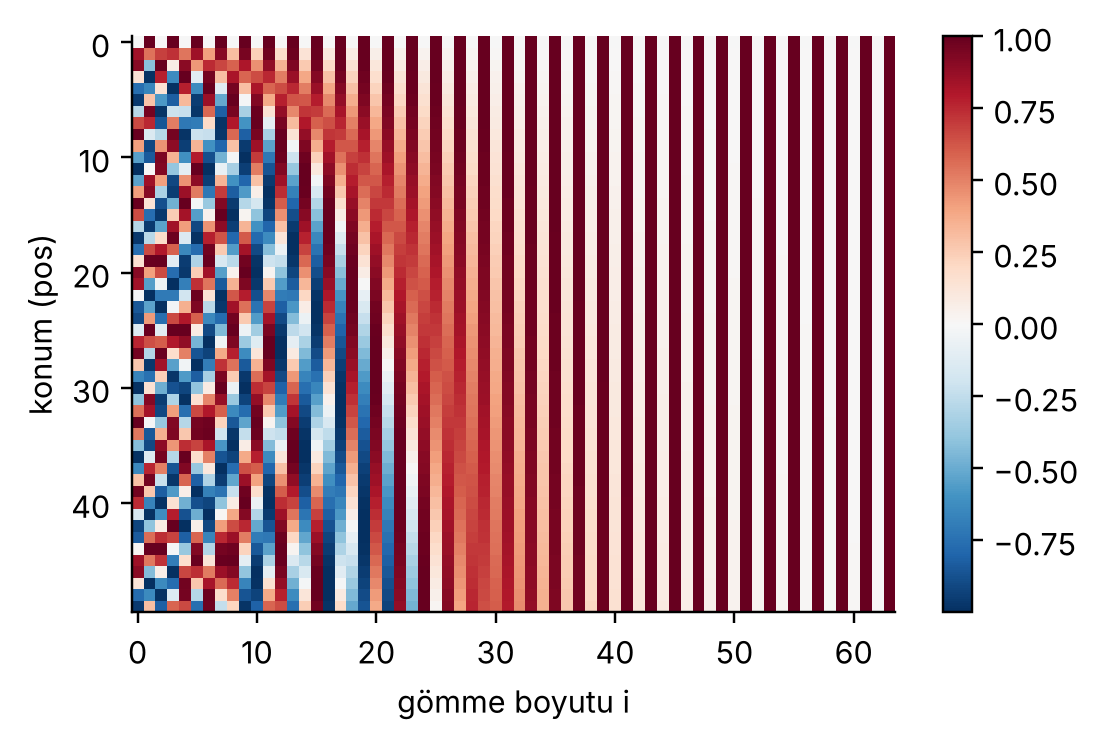

In [4]:
def konum_kodlama(n_konum, d_model):
    pos = np.arange(n_konum)[:, None]
    i2 = np.arange(0, d_model, 2)[None, :]  # 2i
    aci = pos / 10000 ** (i2 / d_model)
    PE = np.zeros((n_konum, d_model))
    PE[:, 0::2] = np.sin(aci)
    PE[:, 1::2] = np.cos(aci)
    return PE

print(konum_kodlama(3, 4)[1:].round(3))  # PE1, PE2
plt.figure(figsize=(5.6, 3.4))
plt.imshow(konum_kodlama(50, 64), cmap="RdBu_r",
           aspect="auto")
plt.xlabel("gömme boyutu i"); plt.ylabel("konum (pos)")
plt.colorbar(); plt.grid(False); plt.show()

## 4. Deney: konum kodlaması olmadan öz-dikkat sırayı görür mü?
Tokenların sırasını karıştırıp öz-dikkat çıktısını karşılaştıralım.

In [5]:
rng = np.random.default_rng(1)
X = rng.standard_normal((3, 4))          # 3 token, d = 4
Wq, Wk, Wv = rng.standard_normal((3, 4, 4))
oz = lambda X: dikkat(X @ Wq, X @ Wk, X @ Wv)[0]

p = [2, 0, 1]                    # tokenların sırasını karıştır
print("konumsuz:", np.allclose(oz(X)[p], oz(X[p])))

PE = konum_kodlama(3, 4)         # konum kodlaması ekle
print("konumlu :", np.allclose(oz(X + PE)[p], oz(X[p] + PE)))

konumsuz: True
konumlu : False


## 5. RoPE sezgisi: döndürerek konum vermek
Llama, Qwen, Mistral gibi modeller sorgu ve anahtar vektörlerini konumlarıyla orantılı bir açıyla döndürür. Sonuç: q·k çarpımı yalnızca iki tokenın **arasındaki uzaklığa** bağlı kalır.

In [6]:
def dondur(v, m, teta=1.0):
    """2B vektörü m·θ açısıyla döndür (RoPE'nin özü)."""
    a = m * teta
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    return R @ v

q, k = np.array([1.0, 0.5]), np.array([0.8, -0.2])
for m, n in [(2, 0), (5, 3), (12, 10)]:      # hepsinde m - n = 2
    print(f"q konum {m:2d} · k konum {n:2d} = {dondur(q, m) @ dondur(k, n):.4f}")
print(f"q konum  5 · k konum  0 = {dondur(q, 5) @ dondur(k, 0):.4f}   (uzaklık 5)")

q konum  2 · k konum  0 = -0.8369
q konum  5 · k konum  3 = -0.8369
q konum 12 · k konum 10 = -0.8369
q konum  5 · k konum  0 = 0.7739   (uzaklık 5)


## 6. PyTorch ile çok başlı dikkat ve bir Transformer bloğu (Çözümlü Örnek 13.3)

In [7]:
import torch
from torch import nn

x = torch.randn(2, 10, 512)      # (yığın, dizi uzunluğu, d_model)
mha = nn.MultiheadAttention(embed_dim=512, num_heads=8,
                            batch_first=True)
y, agirlik = mha(x, x, x)        # öz-dikkat: Q = K = V = x
print(tuple(y.shape), tuple(agirlik.shape))

blok = nn.TransformerEncoderLayer(d_model=512, nhead=8,
                                  dim_feedforward=2048,
                                  batch_first=True)
say = lambda m: sum(p.numel() for p in m.parameters())
print("toplam:", say(blok))
print("dikkat:", say(blok.self_attn),
      "| FFN:", say(blok.linear1) + say(blok.linear2))

(2, 10, 512) (2, 10, 10)
toplam: 3152384
dikkat: 1050624 | FFN: 2099712


## 7. Nedensel (GPT tarzı) maske

In [8]:
nedensel = np.triu(np.ones((3, 3), dtype=bool), k=1)
print(nedensel.astype(int))               # 1: gizlenen konum
print(dikkat(Q, K, V, nedensel)[1].round(3))

[[0 1 1]
 [0 0 1]
 [0 0 0]]
[[1.    0.    0.   ]
 [0.33  0.67  0.   ]
 [0.248 0.248 0.503]]


## 8. Katman normalizasyonu

In [9]:
ln = nn.LayerNorm(4, elementwise_affine=False)   # γ = 1, β = 0
x = torch.tensor([[2., 4., 6., 8.]])
print(ln(x).numpy().round(3))

[[-1.342 -0.447  0.447  1.342]]


## 9. Modern bloğun iki yeniliği: RMSNorm ve SwiGLU
Llama 3 gibi modeller LayerNorm yerine RMSNorm, GELU'lu FFN yerine üç matrisli SwiGLU kullanır.

In [10]:
x = torch.tensor([2., 4., 6., 8.])
rms = x / torch.sqrt((x ** 2).mean() + 1e-6)     # RMSNorm (γ = 1): ortalama çıkarılmaz
print("RMSNorm  :", rms.numpy().round(3))
print("LayerNorm:", nn.LayerNorm(4, elementwise_affine=False)(x).numpy().round(3))

d, dff = 4096, 14336                             # Llama 3 8B boyutları
gelu_ffn = 2 * d * (4 * d)                       # klasik FFN: 2 matris, ara boyut 4d
swiglu = 3 * d * dff                             # SwiGLU: 3 matris (kapı, yukarı, aşağı)
print(f"klasik FFN: {gelu_ffn / 1e6:.1f} M | SwiGLU FFN: {swiglu / 1e6:.1f} M parametre / blok")

RMSNorm  : [0.365 0.73  1.095 1.461]
LayerNorm: [-1.342 -0.447  0.447  1.342]
klasik FFN: 134.2 M | SwiGLU FFN: 176.2 M parametre / blok


## 10. GPT-2 küçük modelin parametre sayısı: elle hesap ve PyTorch (Soru 12)
Model `from_config` ile ağırlık indirmeden kurulur; parametre sayısı önceden eğitilmiş modelle aynıdır.

In [11]:
d, dff, V_, L, N = 768, 3072, 50257, 1024, 12
blok_p = 4 * (d * d + d) + (d * dff + dff + dff * d + d) + 2 * 2 * d
elle = N * blok_p + V_ * d + L * d + 2 * d    # + son katman normu
print("blok:", blok_p, "| 12 blok:", N * blok_p)
print("elle toplam:", elle)

from transformers import GPT2Config, GPT2LMHeadModel
gpt2 = GPT2LMHeadModel(GPT2Config())          # ağırlık indirmeden
print("PyTorch    :", say(gpt2))

blok: 7087872 | 12 blok: 85054464
elle toplam: 124439808


PyTorch    : 124439808


## 11. ViT'te yama gömme (Çözümlü Örnek 13.5)
16 × 16 çekirdekli, 16 adımlı bir evrişim, görüntüyü yamalara bölüp her yamayı 768 boyutlu bir vektöre dönüştürür.

In [12]:
yama = nn.Conv2d(3, 768, kernel_size=16, stride=16)
goruntu = torch.randn(1, 3, 224, 224)
z = yama(goruntu).flatten(2).transpose(1, 2)    # (yığın, yama, D)
print(z.shape, "| parametre:", say(yama))

torch.Size([1, 196, 768]) | parametre: 590592


## 12. Transformer ailesinin parametre sayıları
Her model rastgele ağırlıklarla kurulur (indirme yok); sayılar önceden eğitilmiş sürümlerle aynıdır.

In [13]:
from transformers import (BertConfig, BertModel, T5Config,
    T5ForConditionalGeneration, CLIPConfig, CLIPModel)
from torchvision.models import vit_b_16, swin_t

modeller = {
    "BERT-Base": lambda: BertModel(BertConfig()),
    "T5-small": lambda: T5ForConditionalGeneration(T5Config()),
    "ViT-B/16": lambda: vit_b_16(weights=None),
    "Swin-T": lambda: swin_t(weights=None),
    "CLIP ViT-B/32": lambda: CLIPModel(CLIPConfig()),
}
for ad, kur in modeller.items():
    print(f"{ad:14s} {say(kur()) / 1e6:6.1f} M")
print(f"{'GPT-2 küçük':14s} {say(gpt2) / 1e6:6.1f} M")

BERT-Base       109.5 M


T5-small         60.5 M


ViT-B/16         86.6 M


Swin-T           28.3 M


CLIP ViT-B/32   151.3 M
GPT-2 küçük     124.4 M


### Alıştırma (Değerlendirme Soruları 8 ve 11)
Önce elle çözün, sonra çalıştırıp karşılaştırın.

In [ ]:
q = np.array([[1., 1.]])
K8 = np.array([[1., 1.], [1., -1.]])
V8 = np.array([[4., 0.], [0., 4.]])
c8, a8 = dikkat(q, K8, V8)
print("Soru 8 :", a8.round(3), c8.round(2))
x11 = torch.tensor([[1., 2., 3., 6.]])
print("Soru 11:", ln(x11).numpy().round(3))

# PROJE · Sıfırdan mini GPT
Bu bölümde PyTorch ile **karakter düzeyinde** küçük bir GPT yazıp eğiteceğiz. Adımlar: veri ve sözlük → yığınlar → tek dikkat başı → çok başlı dikkat → Transformer bloğu → model → üretim döngüsü → eğitim → sıcaklık → dikkat haritası.

## P1. Eğitim metni
Ders notlarımızın düzyazı kısmından yaklaşık 80 bin karakter. Kendi metninizle denemek için `metin` değişkenini değiştirebilirsiniz (en az birkaç on bin karakter önerilir).

In [15]:
metin = """Yapay zekâ, son on yılda bilgisayar biliminin en hızlı gelişen alanı oldu. Telefonunuzun kilidini açan yüz tanıma sistemi, e-posta kutunuzdaki istenmeyen posta filtresi, hastanelerde tümörleri işaretleyen görüntü analiz yazılımları ve sohbet ettiğiniz büyük dil modelleri aynı temel fikre dayanır: verilerden öğrenen modeller. Bu ders notları, Yazılım Mühendisliği 4. sınıf öğrencilerinin bu fikri hem kavramsal hem de hesaplama düzeyinde kavraması için hazırlandı. Notlar 14 haftalık ders planına göre düzenlenmiştir. İlk yedi hafta makine öğrenmesinin ve yapay sinir ağlarının temellerini kapsar: veri ve öğrenme türleri, regresyon, sınıflandırma, model değerlendirme, sinir ağları ve geri yayılım. İkinci yarıda bu temellerin üzerine görüntü işleme, evrişimli sinir ağları (CNN), görüntü segmentasyonu, doğal dil işleme, Transformer mimarisi ve büyük dil modelleri (LLM) inşa edilir. Her hafta bir öncekinin üzerine kurulduğu için konuları sırasıyla ça-
Bu dersteki amacımız formül ezberlemek değil, bir modelin neden ve nasıl çalıştığını anlamaktır. Bu yüzden her haftada adım adım çözülmüş sayısal örnekler bulacaksınız. Bu örnekleri yalnızca okumayın; kâğıt, kalem ve hesap makinesiyle kendiniz de çözün. Sınavlardaki hesaplama soruları bu örneklerin benzerleridir. Haftaların içindeki kısa Python kodları ise laboratuvar uygulamalarına hazırlık niteliğindedir; kodları kendi bilgisayarınızda ya da Google Colab üzerinde çalıştırarak sonuçları notlardaki elle yapılmış hesaplarla karşılaştırmanız, konuyu pekiştirmenin en iyi yoludur.
Vize ve final sınavları bu notlardaki konular, tanımlar, çözümlü örnekler ve her haftanın sonundaki değerlendirme soruları esas alınarak hazırlanır. Önerilen vize kapsamı 1-7. haftalardır; final sınavı tüm haftaları kapsar.
Her hafta aynı yapıyı izler. Haftanın başında o haftanın kazanımları ve anahtar kavramları listelenir; ardından konu anlatımı, şekiller ve çözümlü örnekler gelir. Hafta, kısa bir özet ve değerlendirme soruları ile biter. Sorular üç gruptur: (A) çoktan seçmeli sorular, (B) kısa cevaplı ve hesaplama soruları, (C) birden çok kavramı birleştiren ileri düzey sorular. Soruların cevapları Ek D'deki cevap anahtarında yer alır; önce kendiniz çözmeye çalışın, sonra kontrol edin. Metin içinde farklı amaçlara hizmet eden renkli kutular kullanılmıştır:
Konunun matematiksel arka planını, türetmeleri ve ileri düzey hesaplamaları içeren kutulardır. Temel anlatımı kesintiye uğratmadan bir adım daha derine inmek isteyenler içindir; sınavlardaki ileri düzey sorular bu kutulardaki içerikten yararlanır.
Yuvarlama: Ara adımlarda genellikle 3-4 anlamlı basamak tutulmuştur. Sınavda kendi yuvarlamanızdan kaynaklanan küçük farklar sorun değildir. Terimler: Türkçe terimlerin İngilizce karşılıkları ilk geçtikleri yerde parantez içinde verilmiştir. Tüm terimler Ek C'deki sözlükte alfabetik olarak toplanmıştır. Görseller: Fotoğraf örnekleri, açık kaynaklı scikit-image kütüphanesinin örnek görüntülerinden alınmıştır. Diğer tüm şekil ve grafikler bu notlar için hazırlanmıştır.
Bu ders; yapay zekânın temel kavramlarını, makine öğrenmesi ve derin öğrenme yöntemlerini, görüntü ve metin verileri üzerinde çalışan modern mimarileri (CNN, Transformer, büyük dil modelleri) sezgisel ve hesaplamalı bir bakışla tanıtmayı amaçlar. Ders sonunda öğrencilerin bir yapay
zekâ problemini doğru öğrenme türüyle eşleştirebilmesi, temel modelleri elle ve kodla uygulayabilmesi ve modellerin başarımını doğru metriklerle yorumlayabilmesi hedeflenir.
Her dersten önce ilgili haftanın kazanımlarını ve özetini okuyun; dersten sonra anlatımı ve çözümlü örnekleri ayrıntılı çalışın. Çözümlü örnekleri önce kendiniz çözün, sonra çözümle karşılaştırın. Değerlendirme sorularını cevap anahtarına bakmadan çözün; yanlış yaptığınız soruların konu-
Python kodlarını çalıştırın, parametreleri değiştirerek sonucun nasıl değiştiğini gözlemleyin. Ek B'deki formül özetini sınavdan önce tekrar listesi olarak kullanın.
geleneksel programlama ile makine öğrenmesi yaklaşımını karşılaştırabilecek, yapay zekânın tarihsel gelişimindeki kilometre taşlarını sıralayabilecek, akıllı ajan kavramını PEAS çerçevesiyle tanımlayabilecek, A gibi arama algoritmalarının çalışma mantığını açıklayıp küçük bir haritada uygulaya-
"Zekâ" kelimesini tanımlamak bile kolay değildir: Bir satranç ustasının hamle seçmesi, bir çocuğun yürümeyi öğrenmesi, bir doktorun röntgen filminde kırığı fark etmesi ya da bir arkadaşınızın şakanızı anlaması farklı zekâ biçimleridir. Yapay zekâ alanı bu yeteneklerin bir bölümünü bilgisayarlarla gerçekleştirmeyi amaçlar. Terimi ilk kez kullanan John McCarthy yapay zekâyı "akıllı makineler, özellikle de akıllı bilgisayar programları yapma bilimi ve mühendisliği" olarak tanımlamıştır.
Yapay zekâ (artificial intelligence, AI), normalde insan zekâsı gerektiren görevleri -algılama, öğrenme, akıl yürütme, problem çözme, karar verme ve dil anlama gibi- yerine getirebilen bilgisayar sistemleri geliştirmeyi amaçlayan bilim ve mühendislik dalıdır.
Yapay zekâ ders kitaplarının en bilineni olan Russell ve Norvig'in kitabı, alandaki tanımları iki soruya göre dört gruba ayırır: Sistem düşünmeye mi yoksa davranmaya mı odaklanıyor? Başarı ölçütü insana benzemek mi yoksa rasyonel (en doğru) olmak mı? Tablo 1.1 bu dört yaklaşımı özetler.
Alan Turing, 1950 yılında yayımladığı "Computing Machinery and Intelligence" makalesinde "Makineler düşünebilir mi?" sorusunun belirsiz olduğunu savunarak yerine ölçülebilir bir deney önermiştir: taklit oyunu (imitation game). Bugün Turing testi (Turing test) olarak bilinen bu deneyde bir sorgulayıcı, göremediği iki tarafla yalnızca yazılı mesajlarla konuşur (Şekil 1.1). Taraflardan biri insan, diğeri makinedir. Sorgulayıcı hangisinin makine olduğunu güvenilir biçimde ayırt edemiyorsa makine testi geçmiş sayılır.
Filozof John Searle (1980), Turing testine karşı ünlü "Çin Odası" düşünce deneyini önermiştir: Çince bilmeyen bir kişi, bir kural kitabını izleyerek kendisine verilen Çince sorulara kusursuz Çince cevaplar üretebilir; ancak yine de söylediklerinin hiçbirini anlamaz. Searle'e göre davranışı taklit etmek, anlamak demek değildir. Bu tartışma, büyük dil modelleri çağında yeniden
Yapay zekâ sistemleri yeteneklerinin genişliğine göre üç düzeyde incelenir (Tablo 1.2). Günümüzde kullanılan sistemlerin büyük çoğunluğu belirli bir görev için tasarlanmış dar yapay zekâ (narrow AI) örnekleridir. Büyük dil modelleri çok sayıda farklı görevi yerine getirebildikleri için "genel amaçlı" olarak nitelendirilse de insan düzeyinde genel yapay zekâya (artificial general intelligence, AGI) ulaşılıp ulaşılmadığı hâlâ tartışma konusudur.
Bu üç terim günlük dilde çoğu zaman birbirinin yerine kullanılır; oysa aralarında iç içe bir ilişki vardır (Şekil 1.2). Yapay zekâ en geniş kavramdır ve öğrenmeyen sistemleri de (örneğin el ile yazılmış kurallarla çalışan uzman sistemler veya arama algoritmaları) kapsar. Makine öğrenmesi yapay zekânın, derin öğrenme de makine öğrenmesinin bir alt alanıdır.
Makine öğrenmesi (machine learning, ML), bilgisayarların açıkça programlanmadan, verilerden ve deneyimden öğrenerek bir görevdeki başarımlarını artırmasını sağlayan yöntemleri incele-
Tom Mitchell (1997) daha biçimsel ve sınavlarda sıkça sorulan bir tanım vermiştir: Bir bilgisayar programı, T görevlerindeki P ölçütüyle ölçülen başarımı E deneyimiyle artıyorsa, bu program E deneyiminden öğreniyor denir. Burada T görev (task), P performans ölçütü (performance), E ise deneyimdir
E (deneyim): Ziraat uzmanlarınca etiketlenmiş binlerce yaprak fotoğrafı. P (performans): Daha önce görülmemiş test fotoğraflarında doğru sınıflandırılanların
Geleneksel programlamada yazılım mühendisi problemi çözen kuralları kendisi yazar; bilgisayar bu kuralları verilere uygulayarak cevap üretir. Makine öğrenmesinde ise bilgisayara veriler ve bu verilere ait doğru cevaplar (etiketler) verilir; bilgisayar bu ikisi arasındaki ilişkiyi, yani kuralları, kendisi çıkarır (Şekil 1.3). Öğrenilen bu kurallar kümesine model (model) denir ve model daha sonra yeni veriler için tahmin yapmakta kullanılır.
Bu farkı bir istenmeyen e-posta (spam) filtresi üzerinden düşünelim. Kural tabanlı bir filtre "konu satırında kazandınız geçiyorsa spam olarak işaretle" gibi yüzlerce kural içerir. Bu yaklaşımın üç temel sorunu vardır: (i) kurallar zamanla çoğalır ve bakımı zorlaşır, (ii) spam gönderenler kelimeleri değiştirerek ("kazndınız") kuralları kolayca atlatır, (iii) her dil ve her yeni saldırı türü için kural yazmak gerekir. Makine öğrenmesi tabanlı bir filtre ise kullanıcıların "spam" olarak işaretlediği binlerce e-postadan hangi kelime ve özelliklerin spam ile ilişkili olduğunu kendisi öğrenir ve yeni örnekler geldikçe yeniden eğitilerek güncellenir.
Derin öğrenme (deep learning, DL), çok sayıda katmandan oluşan yapay sinir ağlarıyla verinin basitten karmaşığa doğru hiyerarşik temsillerini otomatik olarak öğrenen makine öğrenmesi
Klasik makine öğrenmesi ile derin öğrenme arasındaki en önemli fark, öznitelik (feature) adı verilen ve modele girdi olarak verilen ölçülebilir özelliklerin nasıl elde edildiğidir. Klasik yaklaşımda uzman bir insan, örneğin bir görüntüden kenar yoğunluğu, renk histogramı veya doku ölçüleri gibi öznitelikleri elle tasarlar (öznitelik mühendisliği (feature engineering)). Derin öğrenmede ise ağ, ham pikselleri girdi olarak alır ve hangi özniteliklerin önemli olduğunu eğitim sırasında kendisi öğrenir
Son yıllarda en çok konuşulan alt alan ise üretken yapay zekâdır (generative AI): Bu modeller yalnızca sınıflandırma veya tahmin yapmakla kalmaz, eğitim verisine benzeyen yeni metin, görüntü, ses ve kod üretir. ChatGPT, Gemini ve Claude gibi sohbet asistanlarının temelindeki büyük dil modellerini 14. haftada ayrıntılı olarak inceleyeceğiz.
Yapay zekânın tarihi düz bir çizgide ilerlememiş; büyük beklentilerle geçen "bahar" dönemleri ile hayal kırıklığı ve fon kesintileriyle geçen YZ kışları (AI winters) birbirini izlemiştir. Şekil 1.5 başlıca kilometre taşlarını özetlemektedir. Tarihçeden çıkarılacak en önemli ders şudur: Derin öğrenmenin 2012'den sonraki yükselişi tek bir buluşa değil, üç etkenin aynı anda olgunlaşmasına dayanır.
2. Hesaplama gücü: Başlangıçta bilgisayar oyunları için geliştirilen grafik işlem birimleri (GPU), sinir ağlarının ihtiyaç duyduğu paralel matris çarpımlarını çok hızlı yapabiliyordu. 3. Algoritmik gelişmeler: ReLU aktivasyonu, dropout, daha iyi ağırlık başlatma ve optimizasyon yöntemleri derin ağların eğitimini kararlı hâle getirdi.
2024 Nobel Fizik Ödülü, yapay sinir ağlarıyla makine öğrenmesini mümkün kılan temel keşifleri nedeniyle John Hopfield ve Geoffrey Hinton'a verildi. Aynı yıl Nobel Kimya Ödülü'nün yarısı protein yapısı tahmini yapan AlphaFold modeli için Demis Hassabis ve John Jumper'a, diğer yarısı ise hesaplamalı protein tasarımı için David Baker'a verildi. Yapay zekâ böylece temel bilimlerin en prestijli ödüllerine konu oldu.
Modern yapay zekâda sistemler genellikle ajan (agent) kavramıyla modellenir. Ajan, çevresini algılayıcılar aracılığıyla algılayan ve çevresi üzerinde eyleyiciler aracılığıyla eylemde bulunan her şeydir (Şekil 1.6). Bir robot süpürge, bir satranç programı ya da bir sohbet asistanı birer ajandır. Bir ajan tasarlarken önce görev ortamını tanımlamak gerekir. Bunun için kullanılan çerçeveye, İngilizce bileşen adlarının baş harflerinden oluşan PEAS (Performance, Environment, Actuators, Sensors) denir. Bu çerçeve dört soruyu yanıtlar: Başarı neyle ölçülecek (performans ölçütü)? Ajan nerede çalışacak (ortam)? Hangi araçlarla eylemde bulunacak (eyleyiciler)? Çevreyi nasıl algılayacak
Ajanın çalıştığı ortamın özellikleri tasarım zorluğunu belirler. Ortam tam gözlemlenebilir (satranç tahtasının tamamı görünür) ya da kısmi gözlemlenebilir (taksi, köşenin arkasını göremez); deterministik (aynı hamle hep aynı sonucu verir) ya da stokastik (yayanın ne yapacağı kesin değildir); statik ya da dinamik olabilir. Otonom sürüş; kısmi gözlemlenebilir, stokastik ve dinamik bir ortam olduğu için en zor yapay zekâ problemlerinden biridir.
Makine öğrenmesi yaygınlaşmadan önce yapay zekânın temel aracı arama (search) idi ve bugün de rota planlama, oyun oynama ve otomatik planlama gibi birçok problem arama ile çözülür. Bir arama probleminde bir başlangıç durumu, her durumda uygulanabilecek eylemler, eylemlerin maliyetleri ve bir hedef vardır. Amaç, başlangıçtan hedefe giden en düşük maliyetli eylem dizisini bulmaktır. Haritada iki şehir arasındaki en kısa yol, 8-bulmacasının çözümü veya bir robotun engellerin arasından geçişi bu biçimde modellenir. Arama algoritmaları iki gruba ayrılır. Bilgisiz (uninformed) algoritmalar hedefe ne kadar yakın olduklarını bilmeden ilerler: Genişlik öncelikli arama (BFS) durumları başlangıçtan uzaklıklarına göre katman katman gezer; derinlik öncelikli arama (DFS) bir dalı sonuna kadar izler; tek biçimli maliyet araması (UCS) her adımda o ana kadarki toplam maliyeti g(n) en küçük olan durumu genişletir. Bilgili (informed) algoritmalar ise bir sezgisel fonksiyon (heuristic function) h(n) kullanır: h(n), n durumundan hedefe kalan maliyetin bir tahminidir (ör. haritada kuş uçuşu uzaklık). En ünlü bilgili arama algoritması olan A araması (A search), her adımda
değeri en küçük olan durumu genişletir. Sezgisel fonksiyon gerçek kalan maliyeti hiçbir zaman aşmıyorsa (kabul edilebilir sezgisel), A en düşük maliyetli çözümü bulmayı garanti eder.
Aşağıdaki haritada şehirler arası yol maliyetleri ve her şehrin hedef G'ye kuş uçuşu uzaklık tahmini h verilmiştir. A algoritmasıyla S'den G'ye en ucuz yolu bulunuz.
dönüşür ve aynı sonucu genellikle daha fazla düğüm genişleterek bulur (bu küçük haritada her iki yöntem de beş düğümün tamamını genişletir; fark büyük haritalarda ortaya çıkar).
Arama, problemin kurallarının açıkça bilindiği durumlarda (harita, satranç, bulmaca) çok güçlüdür; öğrenme ise kuralların veriden çıkarılması gerektiğinde devreye girer. Modern sistemler ikisini birleştirir: AlphaGo, hamle olasılıklarını derin bir ağla tahmin eder, en iyi hamleyi ise bu tahminlerle yönlendirilen bir ağaç araması bulur.
Yapay zekâ bugün hemen her sektörde kullanılmaktadır. Şekil 1.7 bu dönem boyunca inceleyeceğimiz yöntemlerin gerçek hayattaki karşılıklarından bazılarını göstermektedir.
Yapay zekâ sistemleri insanların hayatını doğrudan etkileyen kararlarda (işe alım, kredi onayı, tıbbi teşhis) kullanıldıkça etik sorular da önem kazanmaktadır. Bir yazılım mühendisi olarak geliştireceğiniz sistemlerde aşağıdaki ilkeleri göz önünde bulundurmanız gerekir:
Yanlılık ve adalet: Model, eğitim verisindeki önyargıları öğrenir ve büyütebilir. Örneğin geçmişte çoğunlukla erkek adayların işe alındığı bir şirketin verileriyle eğitilen bir özgeçmiş değerlendirme sistemi, kadın adayları sistematik olarak düşük puanlayabilir. Bu duruma algoritmik yanlılık (algorithmic bias) denir. Gizlilik ve veri koruma: Kişisel verilerin toplanması, saklanması ve işlenmesi yasal düzenlemelere uygun olmalıdır. Türkiye'de bu konuda 6698 sayılı Kişisel Verilerin Korunması Kanunu
Şeffaflık ve açıklanabilirlik: Özellikle derin öğrenme modelleri "kara kutu" gibi davranabilir. Bir kredi başvurusunu reddeden modelin bu kararı neden verdiğini açıklayabilmesi gerekir. Bu ihtiyaç açıklanabilir yapay zekâ (explainable AI, XAI) alanını doğurmuştur. Sorumluluk: Otonom bir aracın karıştığı kazada sorumluluğun kime (üretici, yazılımcı, kullanıcı) ait olduğu hukuki bir sorudur. Avrupa Birliği'nin Yapay Zekâ Yasası (AI Act), sistemleri risk düzeyine göre sınıflandıran ilk kapsamlı düzenlemelerden biridir. Kötüye kullanım: Gerçeğinden ayırt edilmesi zor sahte ses ve videolar (deepfake), dezenformasyon ve otomatik siber saldırılar ciddi riskler oluşturur. Akademik dürüstlük: Ödev ve projelerde üretken yapay zekâ araçlarını kullanırken ders kurallarına uymalı, kullanımı açıkça belirtmeli ve üretilen içeriğin doğruluğunu mutlaka kontrol
"Çöp girer, çöp çıkar" (garbage in, garbage out) ilkesi yapay zekâda da geçerlidir. Hatalı, eksik veya yanlı verilerle eğitilen bir model, ne kadar karmaşık olursa olsun güvenilir sonuçlar
Bu derste göreceğimiz hemen her model; girdileri sayı listeleri, yani vektörler (vectors) olarak alır ve bunlar üzerinde matris işlemleri yapar. Bir görüntü piksel değerlerinden, bir cümle kelime temsillerinden, bir hasta kaydı ise ölçüm değerlerinden oluşan bir vektöre dönüştürülür. Bu nedenle ilk haftada iki temel işlemi hatırlayalım (ayrıntılı tekrar için Ek A'ya bakınız). İç çarpım (dot product): Aynı boyuttaki iki vektörün karşılıklı elemanları çarpılıp toplanır:
(a) şıkkındaki işlem, 6. haftada göreceğimiz yapay nöronun yaptığı hesabın ta kendisidir: girdileri ağırlıklarıyla çarp, topla ve bias ekle. (c) şıkkı ise aynı anda iki nöronun hesabını yapar.
Yapay zekâ, insan zekâsı gerektiren görevleri yerine getiren sistemler geliştirmeyi amaçlar; modern yaklaşım rasyonel ajan yaklaşımıdır. Turing testi, makinenin yazışmalarda insandan ayırt edilemeyecek davranış sergileyip ser-
Derin öğrenme devrimi; büyük veri, GPU'larla gelen hesaplama gücü ve algoritmik gelişmelerin birleşimiyle 2012'de başladı. Ajan, algılayıcılarıyla çevreyi algılar ve eyleyicileriyle çevreye etki eder; görev ortamı PEAS
A Abartılı beklentilerin karşılanamaması B Dönemin bilgisayarlarının hesaplama gücünün yetersiz olması C Tek katmanlı perceptronun XOR problemini çözemediğinin gösterilmesi D Araştırma fonlarının kesilmesi E Transformer modellerinin eğitim maliyetinin çok yüksek olması
7. Aşağıdakilerden hangisi dar (zayıf) yapay zekâya örnektir? A Her alanda en yetenekli insanları aşan bir sistem B Yalnızca yaprak fotoğraflarından bitki hastalığı tespit eden bir model C İnsan gibi her türlü görevi öğrenip bilgisini başka alanlara aktarabilen bir sistem D Bilinç sahibi olduğu kanıtlanmış bir robot
12. Mitchell'in T-P-E tanımını, bir e-ticaret sitesinde kullanıcılara ürün öneren bir sistem için yazınız. Bu sistemin başarımını yalnızca "tıklama oranı" ile ölçmenin hangi etik ve teknik sorunlara yol açabileceğini tartışınız.
Bu haftanın sonunda öğrenciler; bir veri setinde örnek, öznitelik ve etiket kavramlarını ayırt edebilecek, denetimli, denetimsiz ve pekiştirmeli öğrenmeyi örneklerle açıklayabilecek; bir problemi doğru öğrenme türüyle eşleştirebilecek, sınıflandırma ile regresyon problemlerini ayırt edebilecek, makine öğrenmesi iş akışının adımlarını sıralayabilecek, veriyi eğitim, doğrulama ve test kümelerine ayırmanın amacını ve veri sızıntısı riskini açık-
Pearson korelasyon katsayısını hesaplayıp yorumlayabilecek; dengesiz veri setleri için yeniden örnekleme ve sınıf ağırlığı yaklaşımlarını açıklayabilecektir.
Makine öğrenmesi modelleri kurallarını veriden çıkardığı için verinin yapısını doğru anlamak her şeyin başlangıcıdır. Tablo biçimindeki bir veri setinde (dataset) her satır bir örnek (sample, instance) (gözlem), her sütun bir öznitelik ve tahmin etmek istediğimiz sütun ise etiket (label) ya da hedef
Belirleyici olan girdinin değil, çıktının (etiketin) türüdür. "Bir hastanın tümörü iyi huylu mu, kötü huylu mu?" sorusu sınıflandırma; "tümörün çapı kaç milimetre?" sorusu ise regresyondur. Çıktı sayı olsa bile sınıf belirtiyorsa (ör. rakam tanımada "7") problem sınıflandırmadır.
Denetimsiz öğrenmede (unsupervised learning) verilerin etiketi yoktur. Model, verinin içindeki yapıyı, grupları veya örüntüleri kendi başına keşfetmeye çalışır.
En yaygın denetimsiz görevler şunlardır: benzer örnekleri gruplayan kümeleme (clustering) (ör. müşteri segmentasyonu), çok boyutlu veriyi daha az boyutla temsil eden boyut indirgeme (dimensionality reduction) ve olağan dışı örnekleri bulan anomali tespiti (anomaly detection). Şekil 2.2 denetimli ve denetimsiz öğrenmeyi karşılaştırmaktadır.
Pekiştirmeli öğrenmede (reinforcement learning) bir ajan, çevresiyle deneme-yanılma yoluyla etkileşime girer. Her eyleminin ardından bir ödül (reward) (ya da ceza) alır ve uzun vadede toplam ödülü en üst düzeye çıkaran davranış stratejisini (policy) öğrenir.
Pekiştirmeli öğrenmede doğru cevap önceden verilmez; ajan yalnızca yaptığı şeyin ne kadar iyi olduğunu ödül sinyalinden anlar (Şekil 2.3). Oyun oynayan programlar (AlphaGo), robotların yürümeyi öğrenmesi ve büyük dil modellerinin insan tercihleriyle hizalanması (RLHF, 14. hafta) bu
Etiketleme çoğu zaman pahalıdır: Bir radyoloğun binlerce MR görüntüsünü tek tek işaretlemesi haftalar sürer. Yarı denetimli öğrenme (semi-supervised learning), az sayıda etiketli örneği çok sayıda etiketsiz örnekle birlikte kullanır. Öz-denetimli öğrenmede (self-supervised learning) ise etiket verinin kendisinden üretilir. Örneğin bir cümlenin sonraki kelimesini tahmin etmek için etikete gerek yoktur, çünkü sonraki kelime metnin içinde zaten vardır. Büyük dil modellerinin ön eğitimi tam
Gerçek bir makine öğrenmesi projesi yalnızca "model eğitmekten" ibaret değildir. Şekil 2.4'deki adımlar bir yazılım projesinin yaşam döngüsüne benzer ve çoğu zaman tekrarlıdır: Değerlendirme sonuçları beklentiyi karşılamazsa veri toplama veya öznitelik adımlarına geri dönülür.
2. Veri toplama: Yeterli miktarda, problemi temsil eden ve mümkünse etiketli veri toplanır. 3. Veri ön işleme: Eksik ve hatalı değerler düzeltilir, veri ölçeklenir ve kodlanır (Bölüm 2.6). 4. Öznitelik mühendisliği: Modelin işini kolaylaştıracak yeni öznitelikler türetilir (ör. doğum ta-
5. Model eğitimi: Uygun algoritma seçilir ve eğitim verisiyle eğitilir. 6. Değerlendirme: Model, eğitimde hiç görmediği test verisi üzerinde uygun metriklerle ölçülür
7. Dağıtım ve izleme: Model bir uygulamaya entegre edilir; zamanla verinin değişmesi (data drift) nedeniyle başarımı izlenir ve gerektiğinde yeniden eğitilir. Bu adımların yazılım mühendisliği disipliniyle yönetilmesine MLOps (machine learning operations) denir.
Sektörde yapılan anketlerde veri bilimcilerin zamanlarının önemli bir bölümünü model geliştirmeye değil, veriyi toplamaya, temizlemeye ve düzenlemeye harcadıkları sıkça dile getirilir. Gerçek projelerde en çok emek isteyen adım genellikle veridir.
Bir modelin gerçek başarısı, eğitim sırasında hiç görmediği veriler üzerindeki başarısıdır. Bu yeteneğe genelleme (generalization) denir. Genellemeyi ölçebilmek için veri seti en baştan üç parçaya ayrılır
Eğitim kümesi (training set): Modelin parametrelerini öğrenmek için kullanılır. Doğrulama kümesi (validation set): Model seçimi ve hiperparametre ayarı (ör. polinom derecesi, öğrenme oranı) için kullanılır. Test kümesi (test set): Yalnızca en sonda, nihai başarımı raporlamak için bir kez kullanılır.
Test verisine ait herhangi bir bilginin eğitim sürecine karışmasına veri sızıntısı (data leakage) denir. Sızıntı, modelin başarısını olduğundan yüksek gösterir ve model gerçek hayatta beklenenden kötü çalışır. Sık görülen örnekler:
Bir model eğitim verisindeki gürültüyü ve rastlantısal ayrıntıları da ezberlerse eğitim verisinde çok başarılı, yeni verilerde ise başarısız olur. Bu duruma aşırı öğrenme (overfitting) denir. Tersine, model verideki ilişkiyi yakalayamayacak kadar basitse hem eğitim hem test verisinde başarısız olur; buna
Sınava yalnızca geçmiş yılların sorularını cevaplarıyla ezberleyerek hazırlanan bir öğrenci, aynı sorular gelirse tam puan alır; soruların sayıları biraz değiştirildiğinde ise çözemez. Bu öğrenci aşırı öğrenmiştir. Konuyu hiç çalışmayan öğrenci ise her durumda başarısızdır (eksik öğrenme). İyi bir model, konuyu anlayan öğrenci gibi yeni sorularda da başarılı olandır.
Aşırı öğrenmeyle mücadele yöntemlerini (düzenlileştirme, çapraz doğrulama) 5. haftada, derin ağlara özgü yöntemleri (dropout, veri artırma) 7. ve 10. haftalarda ayrıntılı olarak inceleyeceğiz.
Gerçek veri setlerinde bazı hücreler boş olabilir (anket sorusunu cevaplamayan kişi, arızalanan sensör). Başlıca çözümler: (i) eksik değer içeren satırları silmek (veri azsa kayıp büyüktür), (ii) sayısal sütunlarda eksik değeri sütunun ortalaması veya medyanı ile doldurmak, (iii) kategorik sütunlarda en sık görülen değerle (mod) doldurmak. Aykırı değerlerin bulunduğu sütunlarda medyan, ortalamaya göre daha güvenilirdir.
arasında değişir. Uzaklık hesabına dayanan yöntemlerde (k-NN, k-means) ve gradyan inişle eğitilen modellerde büyük ölçekli öznitelik baskın hâle gelir. Bu nedenle öznitelikler benzer aralıklara
Modeller sayılarla çalıştığı için "Iğdır", "Kars", "Van" gibi kategorik değerlerin sayıya dönüştürülmesi gerekir. İlk akla gelen yöntem her kategoriye bir tam sayı vermektir (etiket kodlama (label
Ön işlemenin son adımı, özniteliklerin birbiriyle ve etiketle nasıl ilişkili olduğunu incelemektir. İki sayısal değişken arasındaki doğrusal ilişkinin yönünü ve gücünü Pearson korelasyon katsayısı (Pe-
gösterir. Korelasyon matrisi (her öznitelik çifti için r), iki durumda yol göstericidir: Etiketle güçlü korelasyonu olan öznitelikler iyi birer aday tahmin edicidir; birbiriyle çok yüksek korelasyonlu iki öznitelik (ör. metre ve santimetre cinsinden boy) ise aynı bilgiyi taşıdığından biri atılabilir.
Sınıflandırma problemlerinde sınıfların örnek sayıları çoğu zaman çok farklıdır: Kredi kartı işlemlerinin binde biri sahtedir, tıbbi taramaların küçük bir kısmı hastalık içerir. Bu tür dengesiz veri (imbalanced data) setlerinde model, çoğunluk sınıfını tahmin ederek yüksek doğruluğa ulaşabilir ve azınlık sınıfını hiç öğrenmeyebilir. Başlıca çözümler:
Yeniden örnekleme: Çoğunluk sınıfından örnek atmak (undersampling) veya azınlık sınıfını çoğaltmak (oversampling). SMOTE yöntemi, azınlık örneklerinin arasında ara noktalar üreterek sentetik örnekler oluşturur. Yeniden örnekleme yalnızca eğitim kümesine uygulanır; test kümesi gerçek dağılımı yansıtmalıdır. Sınıf ağırlıkları: Kayıp fonksiyonunda azınlık sınıfının hataları daha ağır cezalandırılır. Yaygın
Yüzlerce özniteliği olan bir veri setinde öznitelikler çoğu zaman birbirine bağımlıdır ve veri aslında daha düşük boyutlu bir yapıda yaşar. Temel bileşen analizi (principal component analysis, PCA), veriyi varyansın en büyük olduğu yönlere (temel bileşenlere) izdüşürür: İlk bileşen verinin en çok yayıldığı doğrultudur, ikinci bileşen ona dik ve kalan varyansı en çok açıklayan doğrultudur; bu böyle devam eder. Bileşenler, standartlaştırılmış verinin kovaryans matrisinin özvektörleridir; her bileşenin açıkladığı varyans oranı ilgili özdeğerle orantılıdır. Uygulamada ilk k bileşen alınarak (ör. toplam varyansın %95'ini açıklayan sayıda) veri d boyuttan k boyuta indirgenir. PCA; görselleştirme (2-3 boyuta indirgeme), gürültü azaltma ve uzaklık tabanlı yöntemleri hızlandırma amacıyla kullanılır. Doğrusal olmayan yapılar için t-SNE ve UMAP gibi görselleştirme yöntemleri tercih edilir.
Veri setinde satırlar örnek, sütunlar öznitelik, tahmin edilen sütun etikettir. Denetimli öğrenmede etiketler bilinir; etiket kategorikse sınıflandırma, sürekliyse regresyon
melerine ayrılır. Test bilgisinin eğitime karışması veri sızıntısıdır. Aşırı öğrenmede eğitim hatası çok düşük, test hatası yüksektir; eksik öğrenmede ikisi de
Dengesiz veride yeniden örnekleme (yalnızca eğitim kümesinde), sınıf ağırlıkları ve doğruluk dışı metrikler kullanılır. PCA, veriyi en çok varyans taşıyan yönlere izdüşürerek boyut
2. Aşağıdakilerden hangisi bir regresyon problemidir? A Bir tweet'in olumlu ya da olumsuz olduğunu belirlemek B Bir yaprak fotoğrafındaki hastalık türünü belirlemek
6. Aşağıdakilerden hangisi bir veri sızıntısı örneğidir? A Veriyi eğitim ve test kümelerine katmanlı olarak bölmek B Standardizasyon için ortalama ve standart sapmayı, veriyi bölmeden önce tüm veri
C Hiperparametreleri doğrulama kümesine göre seçmek D Eksik değerleri eğitim kümesinin medyanıyla doldurmak E Test kümesini yalnızca en sonda bir kez kullanmak
A Eksik öğrenme; modeli daha karmaşık hâle getirmek B Aşırı öğrenme; daha fazla veri toplamak veya modeli basitleştirmek C Eksik öğrenme; eğitimi erken durdurmak D Aşırı öğrenme; test kümesini eğitime eklemek E Model idealdir; değişiklik gerekmez
ruluğu nedir ve bu model neden işe yaramaz? (b) Çoğunluk sınıfı, sahte işlemlerin dört katı olacak şekilde alt örneklenirse eğitim kümesi kaç örnek içerir? (c) Yeniden örnekleme neden test kümesine uygulanmaz?
artık (hata) ve kayıp fonksiyonu kavramlarını açıklayabilecek, en küçük kareler yöntemiyle regresyon katsayılarını elle hesaplayabilecek, MSE, RMSE, MAE ve R2 metriklerini hesaplayıp yorumlayabilecek, gradyan iniş algoritmasının adımlarını uygulayabilecek ve öğrenme oranının etkisini açık-
Regresyon, sürekli bir hedef değişkeni tahmin etmeyi amaçlayan denetimli öğrenme görevidir. Bu ailenin en basit ve en çok kullanılan üyesi doğrusal regresyondur (linear regression). Tek öznitelikli durumda model bir doğrudur:
linde modellenebilir. Bu modelde bina yaşının katsayısının negatif olması, diğer her şey sabitken eski binaların daha ucuz olduğunu söyler. Katsayıların bu şekilde doğrudan yorumlanabilmesi, doğrusal regresyonun en büyük avantajlarından biridir.
bir parabol çizse de w1 , w2 , b parametrelerine göre doğrusal olduğu için yine doğrusal regresyonla çözülür. Buna polinom regresyon (polynomial regression) denir; 2. haftadaki Şekil 2.6 bu
Artıkları tek bir sayıya indirgeyen fonksiyona kayıp fonksiyonu (loss function) denir. Regresyonda en yaygın kayıp, ortalama kare hatadır (mean squared error, MSE):
Ayrıca kare fonksiyonunun türevi kolay alındığından optimizasyon kolaylaşır. Alternatif olarak hataların mutlak değerinin ortalaması (MAE) da kullanılabilir (Şekil 3.2).
Basit doğrusal regresyonda MSE'yi en küçük yapan w ve b değerleri kapalı formda (doğrudan formülle) bulunabilir. Bu yönteme en küçük kareler (least squares) yöntemi denir.
Formül sezgisel olarak şunu söyler: x ortalamanın üzerindeyken y de ortalamanın üzerinde olma eğilimindeyse pay pozitif çıkar ve eğim pozitif olur. b'nin formülü ise en iyi doğrunun her zaman
sayısı on binleri bulduğunda ya da iki öznitelik birbirinin katı olduğunda (matris tekil olur) gradyan iniş tercih edilir. Ayrıca bu kapalı çözüm yalnızca MSE kaybına ve doğrusal modele özgüdür; sinir ağlarında böyle bir formül yoktur ve tek seçenek gradyan iniştir.
R2 formülündeki pay hata kareler toplamı (sum of squared errors, SSE), payda ise toplam kareler toplamıdır (total sum of squares, SST). SST, hiçbir öznitelik kullanmadan her örnek için y tahmin eden en basit modelin hatasıdır. Dolayısıyla R2 , modelimizin bu "tembel" modele göre ne kadar iyi oldu-
ortalamayı tahmin etmekten bile kötüyse (SSE SST) R2 negatif çıkar. Negatif R2 , modelin işe yaramadığının güçlü bir işaretidir. Ayrıca yüksek R2 tek başına modelin doğru olduğunu kanıtlamaz; artıkların grafiğine de bakılmalıdır.
En küçük kareler formülü yalnızca doğrusal regresyon gibi özel modeller için vardır. Lojistik regresyonda ve sinir ağlarında kaybı en küçük yapan parametreleri veren kapalı bir formül yoktur. Bu durumda kullanılan genel amaçlı yöntem gradyan iniştir (gradient descent). Derin öğrenmedeki milyarlarca parametreli modeller de gradyan inişin türevleriyle eğitilir; bu nedenle bu bölüm dersin geri kalanı için kritik öneme sahiptir.
Yoğun siste bir dağın tepesinde olduğunuzu ve vadiye inmek istediğinizi düşünün. Etrafı göremiyorsunuz; ancak ayağınızın altındaki zeminin hangi yöne doğru eğimli olduğunu hissedebiliyorsunuz. Mantıklı strateji, en dik iniş yönünde küçük bir adım atmak ve bunu tekrarlamaktır. Gradyan iniş tam olarak budur: Dağ kayıp fonksiyonu, konumunuz parametreler, eğim gradyan, adım uzunluğunuz ise öğrenme oranıdır.
Burada (eta) öğrenme oranıdır (learning rate). Adımlar, parametreler artık anlamlı ölçüde değişmeyene (yakınsama) ya da belirlenen iterasyon sayısına ulaşılana kadar tekrarlanır.
Öğrenme oranı, eğitimin başarısını belirleyen en önemli hiperparametredir (hyperparameter). Hiperparametre, modelin veriden öğrendiği bir değer değil, eğitimden önce bizim belirlediğimiz bir ayardır. Şekil 3.3 aynı fonksiyonda üç farklı öğrenme oranının davranışını göstermektedir.
öğrenme oranıyla ilerleme çok yavaştır. (b) Uygun öğrenme oranıyla birkaç adımda en küçük noktaya ulaşılır. (c) Çok büyük öğrenme oranıyla adımlar en küçük noktanın üzerinden atlar ve
çok küçükse: Algoritma doğru yönde ilerler ama yakınsamak için çok fazla iterasyon gerekir. uygunsa: Kayıp hızla ve kararlı biçimde azalır. çok büyükse: Algoritma vadinin bir yamacından diğerine sıçrar; salınım yapar ya da ıraksar
Öznitelikler farklı ölçeklerdeyse kayıp yüzeyi bir yönde dik, diğer yönde düz uzamış bir vadiye dönüşür. Gradyan dik yönde büyük olduğu için adımlar vadinin duvarları arasında zikzak çizer; öğrenme oranı dik yöne göre küçük seçilmek zorunda kalır ve düz yönde ilerleme çok yavaşlar.
1/a gerekir. Öznitelik 10 kat büyütülürse a 100 kat büyür ve izin verilen en büyük öğrenme oranı 100 kat küçülür. Z-skoru standardizasyonu (2. hafta) tüm yönlerdeki eğrilikleri birbirine yaklaştırır; böylece tek bir öğrenme oranı her yönde iyi çalışır ve yakınsama hızlanır. Bu nedenle gradyan inişle eğitilen her modelde öznitelik ölçekleme zorunlu bir ön adımdır.
Yığın (batch) gradyan iniş: Her adımda tüm eğitim verisi kullanılır. Kararlıdır ancak büyük veride her adım çok pahalıdır. Stokastik gradyan iniş (stochastic gradient descent, SGD): Her adımda rastgele seçilen tek örnek kullanılır. Adımlar ucuz ama gürültülüdür.
Gradyan iniş fikri yeni değildir: Fransız matematikçi Augustin-Louis Cauchy 1847'de denklem sistemlerini çözmek için bu yöntemi önermiştir. Bugün ChatGPT gibi modelleri eğitirken kullanılan Adam optimizasyon algoritması da özünde Cauchy'nin fikrinin akıllıca geliştirilmiş bir
A Model tüm örnekleri hatasız tahmin etmektedir. B Model, her örnek için hedefin ortalamasını tahmin etmekten daha iyi değildir. C Modelin MSE değeri sıfırdır. D Model aşırı öğrenmiştir. E Öznitelikler ile hedef arasında mükemmel doğrusal ilişki vardır.
10. Öğrenme oranının çok küçük ve çok büyük seçilmesinin sonuçlarını birer cümleyle açıklayınız. Öğrenme oranı neden "parametre" değil "hiperparametre" olarak adlandırılır?
Bu haftanın sonunda öğrenciler; ikili, çok sınıflı ve çok etiketli sınıflandırma problemlerini ayırt edebilecek, lojistik regresyonda sigmoid fonksiyonuyla olasılık hesaplayıp karar verebilecek ve ikili çapraz entropi kaybını hesaplayabilecek, k-en yakın komşu algoritmasını uzaklık hesabıyla elle uygulayabilecek, karar ağaçlarında entropi, Gini ve bilgi kazancı hesaplayarak bölme özniteliğini seçebile-
Naive Bayes sınıflandırıcısıyla sonsal olasılık hesaplayabilecek, destek vektör makinelerinin maksimum marj fikrini açıklayabilecek ve algoritmaları güçlü-zayıf yönleriyle karşılaştırabilecek, çapraz entropi kaybının gradyanını türetebilecek, sürekli bir öznitelik için Gini ile en iyi eşiği bulabilecek ve SVM marjını hesaplayabilecektir.
Sınıflandırmada amaç, bir örneği önceden tanımlı sınıflardan birine (ya da birkaçına) atamaktır. Model, öznitelik uzayını sınıflara karşılık gelen bölgelere ayırır; bu bölgeleri ayıran yüzeye karar sınırı (decision boundary) denir. Sınıflandırma problemleri üç türe ayrılır:
İkili sınıflandırma (binary classification): İki sınıf vardır. Spam/normal, hasta/sağlıklı, geçti/kaldı. Sınıflar genellikle 1 (pozitif) ve 0 (negatif) olarak kodlanır. Çok sınıflı sınıflandırma (multi-class classification): İkiden fazla sınıf vardır ve her örnek tam olarak bir sınıfa aittir. El yazısı rakam tanıma (10 sınıf), bitki hastalığı türü. Çok etiketli sınıflandırma (multi-label classification): Bir örnek aynı anda birden fazla etikete sahip olabilir. Bir fotoğrafta hem "kedi" hem "kanepe" bulunabilir; bir film hem "komedi" hem
Bu hafta dört temel yaklaşımı inceleyeceğiz: olasılık üreten doğrusal bir model (lojistik regresyon), benzerliğe dayanan bir yöntem (k-NN), kurallar üreten bir yöntem (karar ağacı) ve olasılık ku-
lenmiştir. (a) Haftada 3 saat ve 5 saat çalışan öğrencilerin geçme olasılıklarını hesaplayınız ve 0.5 eşiğine göre sınıflandırınız. (b) Karar sınırını bulunuz.
Lojistik regresyonda MSE yerine ikili çapraz entropi (binary cross-entropy) kaybı kullanılır. Bu kayıp, doğru sınıfa verilen olasılığın negatif logaritmasıdır:
Yani güncelleme miktarı, tahmin edilen olasılık ile gerçek etiket arasındaki farkla orantılıdır. Model gradyan inişle (3. hafta) eğitilir. İkiden fazla sınıf olduğunda sigmoid yerine softmax fonksiyonu kullanılır; bunu 7. haftada göreceğiz.
Sigmoid çıktısı ile MSE birlikte kullanıldığında kayıp yüzeyi dışbükey (convex) olmaz ve birçok yerel minimum oluşabilir; ayrıca model çok yanlış olduğunda gradyanlar çok küçülür ve öğrenme yavaşlar. Çapraz entropi bu iki sorunu da ortadan kaldırır.
k-en yakın komşu (k-nearest neighbors, k-NN) algoritması, "bana arkadaşını söyle, sana kim olduğunu söyleyeyim" ilkesine dayanır. Yeni bir örneği sınıflandırmak için eğitim kümesinde ona en yakın k örnek bulunur ve bu komşular arasında en çok görülen sınıf (çoğunluk oylaması) tahmin edilir. Regresyonda ise komşuların hedef değerlerinin ortalaması alınır.
1. Yeni örnek q ile eğitim kümesindeki her örnek arasındaki uzaklığı hesapla. 2. Uzaklıkları küçükten büyüğe sırala ve en yakın k örneği seç. 3. Bu k komşunun sınıflarına bak; en sık görülen sınıfı tahmin olarak döndür.
karar sınırı girintili çıkıntılı olur ve aşırı öğrenme görülür. Büyük k ise karar sınırını aşırı yumuşatır ve küçük sınıfları "yutar" (eksik öğrenme). Uygun k değeri doğrulama kümesi veya çapraz doğrulama (5. hafta) ile seçilir. İki sınıflı problemlerde oyların eşit çıkmaması için k genellikle tek sayı
Tahmin yavaştır: k-NN eğitim sırasında hiçbir şey öğrenmez, yalnızca veriyi saklar (tembel öğrenme (lazy learning)). Her tahminde tüm eğitim örneklerine uzaklık hesaplan-
dığından büyük veride yavaştır. Boyut laneti: Öznitelik sayısı çok arttığında tüm noktalar birbirine benzer uzaklıklarda kalır ve "en yakın komşu" kavramı anlamını yitirir (boyutluluğun laneti (curse of dimensio-
Karar ağacı (decision tree), veriyi "evet/hayır" sorularıyla art arda bölerek sınıflandıran, akış şemasına benzeyen bir modeldir. Ağacın en üstündeki düğüme kök, iç düğümlere karar düğümü, en alttaki düğümlere ise yaprak denir. Her yaprak bir sınıf tahmini içerir. Karar ağaçlarının en büyük avantajı yorumlanabilir olmalarıdır: Bir tahminin neden yapıldığı kökten yaprağa giden yol izlenerek açıkla-
Ağaç kurulurken her düğümde "hangi öznitelikle bölersem ortaya çıkan gruplar en saf olur?" sorusu sorulur. Saf bir düğümde örneklerin hepsi aynı sınıftandır. Saflığı ölçmek için iki ölçü kulla-
Bir A özniteliğine göre bölmenin bilgi kazancı (information gain), ebeveyn düğümün entropisinden çocuk düğümlerin ağırlıklı ortalama entropisinin çıkarılmasıyla bulunur:
Sonuç: IG(Devam) IG(Ödev) olduğundan kök düğümde Devam özniteliği kullanılır. Aynı işlem alt düğümlerde tekrarlanarak Şekil 4.4'deki ağaç elde edilir. (Gini ile de aynı sonuç çıkar:
Yaş, gelir gibi sürekli öznitelikler "x t" biçiminde ikili sorulara dönüştürülür. Aday eşikler, sıralanmış değerlerin ardışık çiftlerinin orta noktalarıdır (yalnızca etiketin değiştiği yerlere bakmak yeterlidir); her aday için safsızlık hesaplanır ve en iyi eşik seçilir. Bu işlem her düğümde, her öznite-
Sınırlandırılmayan bir karar ağacı, her yaprakta tek bir örnek kalana kadar bölmeye devam ederek eğitim verisini ezberleyebilir. Bunu önlemek için en fazla derinlik (maxdepth), bir yapraktaki en az örnek sayısı gibi sınırlar konur ya da ağaç sonradan budanır (pruning). Tek bir ağacın kararsızlığını gidermenin güçlü bir yolu, çok sayıda ağacı bir araya getirmektir. Rastgele orman (random forest), her biri verinin rastgele bir alt örneklemiyle ve özniteliklerin rastgele bir alt kümesiyle eğitilmiş yüzlerce ağacın oylamasıyla karar verir. Birden çok modeli birleştiren bu tür yöntemlere topluluk öğrenmesi (ensemble learning) denir. Rastgele ormanlar ve gradyan artırma (XGBoost, LightGBM) yöntemleri, tablo verilerinde bugün hâlâ en başarılı yöntemler arasındadır.
İki sınıfı ayıran sonsuz sayıda doğru çizilebilir. Destek vektör makineleri (support vector machines, SVM), bu doğrular arasından iki sınıfa da en uzak olanı, yani sınıflar arasındaki boşluğu (marj (margin)) en büyük yapanı seçer (Şekil 4.6). Karar sınırına en yakın olan ve sınırın konumunu belirleyen örneklere destek vektörleri (support vectors) denir; diğer örnekler silinse bile karar sınırı değişmez. Geniş marj, yeni örneklerde daha iyi genelleme sağlar.
ile az hata arasındaki dengeyi ayarlar: Büyük C hataları ağır cezalandırır (dar marj, aşırı öğrenme riski), küçük C marjı genişletir. Veri doğrusal olarak ayrılamıyorsa SVM, çekirdek hilesi (kernel trick) ile veriyi örtük olarak daha yüksek boyutlu bir uzaya taşır ve orada doğrusal bir sınır arar. Bu sınır, orijinal uzayda eğri bir sınıra karşılık gelir. En yaygın çekirdek RBF (Gauss) çekirdeğidir. SVM'ler derin öğrenme öncesi dönemde (1995-2012) en başarılı sınıflandırıcılardandı ve küçük-orta boyutlu veri setlerinde hâlâ
4. k-NN algoritması için aşağıdaki ifadelerden hangisi yanlıştır? A Uzaklık hesabına dayandığı için özniteliklerin ölçeklenmesi önemlidir. B Eğitim aşamasında parametre öğrenmez, veriyi saklar. C k değeri büyüdükçe karar sınırı daha düzgün (yumuşak) hâle gelir. D Tahmin aşaması, eğitim kümesi büyüdükçe yavaşlar.
6. Karar ağacı kurulurken bir düğümde bölme yapılacak öznitelik hangi ölçüte göre seçilir? A En düşük bilgi kazancı B En yüksek bilgi kazancı (veya en düşük ağırlıklı safsızlık) C En fazla kategorisi olan öznitelik
8. Naive Bayes sınıflandırıcısının "naif" olarak adlandırılmasının nedeni nedir? A Yalnızca iki sınıfla çalışabilmesi B Sınıf bilindiğinde özniteliklerin birbirinden bağımsız olduğunu varsayması C Önsel olasılıkları kullanmaması D Gradyan inişle eğitilmesi E Karar sınırının her zaman doğrusal olması
10. Bir düğümde 9 "Evet" ve 5 "Hayır" örneği vardır. Bir öznitelikle bölündüğünde birinci çocukta 6 Evet-2 Hayır, ikinci çocukta 3 Evet-3 Hayır oluşmaktadır. (a) Ebeveyn düğümün entropisini, (b) bu bölmenin bilgi kazancını hesaplayınız.
şilerin ise %5'inde (yanlışlıkla) pozitif sonuç vermektedir. Testi pozitif çıkan birinin gerçekten hasta olma olasılığını Bayes teoremiyle hesaplayınız ve sonucu yorumlayınız.
yazınız, (b) her aday için ağırlıklı Gini safsızlığını hesaplayıp en iyi eşiği seçiniz, (c) tek bir eşikle tüm örneklerin neden doğru sınıflandırılamayacağını açıklayınız.
dengesiz veri setlerinde doğruluğun neden yanıltıcı olduğunu açıklayabilecek, ROC eğrisi ve AUC değerini yorumlayabilecek, karar eşiğinin etkisini tartışabilecek, k-katlı çapraz doğrulamayı uygulayabilecek, yanlılık-varyans ödünleşimini ve L1/L2 düzenlileştirmenin amacını açıklayabilecek, k-ortalamalar (k-means) algoritmasını elle uygulayabilecek ve küme sayısını dirsek yönte-
kesinlik-duyarlılık eğrisinden ortalama kesinliği (AP) hesaplayabilecek, hiperparametre aramasını çapraz doğrulamayla planlayabilecek ve siluet skorunu yorumlayabilecektir.
Bir sınıflandırıcının başarısını ölçmenin akla gelen ilk yolu, doğru tahminlerin oranı olan doğruluktur (accuracy). Ancak doğruluk tek başına yanıltıcı olabilir. Bin kişide 50'sinin hasta olduğu bir tarama programı düşünün. Hiçbir şey öğrenmeden herkese "sağlıklı" diyen bir model %95 doğruluk elde eder; ama tek bir hastayı bile yakalayamaz. Sınıfların sayıca çok farklı olduğu bu tür veri setlerine dengesiz veri seti (imbalanced dataset) denir ve gerçek hayattaki problemlerin çoğu (hastalık teşhisi, dolandırıcılık, arıza tespiti) bu türdendir. Bu nedenle sınıflandırıcıları farklı açılardan ölçen metriklere ihtiyaç vardır.
İkili sınıflandırmada tahminler, gerçek sınıfla karşılaştırıldığında dört gruba ayrılır. Bu dört sayıyı gösteren tabloya karışıklık matrisi (confusion matrix) denir (Şekil 5.1).
Kesinlik (precision) ve duyarlılık (recall, sensitivity) birbirini tamamlayan iki sorunun cevabıdır. Duyarlılık tıpta "hassasiyet" (sensitivity) veya "doğru pozitif oranı" (TPR) olarak da bilinir. F1 skoru (F1 score), iki metriği tek sayıda birleştirir. Harmonik ortalama kullanıldığı için metriklerden biri çok düşükse F1 de düşük çıkar; böylece "yalnızca birinde iyi" olan model ödüllendirilmez.
doğru tespit etmiş, ayrıca 30 sağlıklı kişiye yanlışlıkla "hasta" demiştir. (a) Karışıklık matrisini oluşturunuz. (b) Doğruluk, kesinlik, duyarlılık, özgüllük ve F1 değerlerini hesaplayınız. (c) Herkese "sağlıklı" diyen modelin doğruluğu ve duyarlılığı nedir?
Duyarlılık önceliklidir (FN pahalıdır): kanser taraması, hırsızlık alarmı, salgın tespiti. Bir hastayı kaçırmak, birkaç yanlış alarmdan çok daha maliyetlidir. Kesinlik önceliklidir (FP pahalıdır): spam filtresi (önemli bir e-postayı spam klasörüne atmak), bir müşteriyi haksız yere dolandırıcı ilan etmek, öneri sistemleri. Sınıflar dengesizse doğruluk yerine F1, kesinlik-duyarlılık ve AUC birlikte raporlanmalı-
minleri gösterir ve köşegen doğru tahminleri içerir. Kesinlik, duyarlılık ve F1 her sınıf için "o sınıf pozitif, diğerleri negatif" kabul edilerek ayrı ayrı hesaplanır. Sonra bu değerlerin basit ortalaması alınır (makro ortalama (macro average)) ya da sınıfların örnek sayısına göre ağırlıklı ortalaması alınır (ağırlıklı ortalama). Makro ortalama, küçük sınıflara da büyük sınıflar kadar önem verdiği için dengesiz veride tercih edilir.
Lojistik regresyon gibi modeller bir olasılık üretir ve sınıf kararı bir eşikle verilir. Eşiği düşürmek modeli daha "cesur" yapar: Daha fazla örneğe "pozitif" der, duyarlılık artar ama kesinlik genellikle düşer. Eşiği yükseltmek ise tersini yapar (Şekil 5.2). Varsayılan 0.5 eşiğinin probleme göre en iyi
ROC eğrisi, negatif sınıf çok büyük olduğunda iyimser görünebilir: Binlerce negatif arasında birkaç yüz yanlış pozitif, FPR'yi neredeyse hiç değiştirmez ama kesinliği çökertir. Dengesiz problemlerde bu yüzden kesinlik-duyarlılık eğrisi (precision-recall curve) tercih edilir: Eşik düşürüldükçe elde edilen (duyarlılık, kesinlik) çiftleri çizilir. Eğrinin altındaki alan ortalama kesinlik (average precision, AP) olarak özetlenir ve pratikte, her yeni doğru pozitifin yakalandığı andaki kesinliklerin ortala-
Rastgele bir modelin AP'si pozitif sınıfın oranına eşittir (%1 pozitif içeren veride 0.01); bu yüzden AP, aynı verideki AUC'den çok daha sert bir ölçüttür.
Aynı modelin AUC'si 0.8125 idi; iki metrik farklı soruları yanıtlar. Nesne tespitinde kullanılan mAP (10. hafta) de bu hesabın sınıflar üzerinden ortalamasıdır.
Veriyi bir kez eğitim ve doğrulama kümelerine ayırmak, özellikle küçük veri setlerinde şansa bağlı sonuçlar verebilir: Doğrulama kümesine kolay örnekler düşerse model olduğundan iyi görünür. k-katlı çapraz doğrulama (k-fold cross-validation) bu sorunu şöyle çözer (Şekil 5.4): Eğitim verisi k eşit parçaya (kata) bölünür. Model k kez eğitilir; her seferinde bir kat doğrulama, kalan k - 1 kat eğitim için kullanılır. Sonuçta k başarım değerinin ortalaması ve standart sapması raporlanır. Yaygın
Çapraz doğrulamanın en yaygın kullanımı hiperparametre (hyperparameter) seçimidir: k-NN'deki k, SVM'deki C, ağacın en büyük derinliği, öğrenme oranı gibi eğitimle öğrenilmeyen ayarlar. Izgara arama (grid search) her hiperparametre için bir değer listesi alır ve tüm kombinasyonları çapraz
sayısı hızla patladığından rastgele arama, belirli bir bütçe kadar rastgele kombinasyon dener ve aynı bütçede genellikle ızgaradan daha iyi sonuç verir; çünkü önemsiz hiperparametrelere eşit zaman harcamaz. Önceki denemelerden öğrenerek umut vadeden bölgelere yönelen Bayesçi optimizasyon araçları (Optuna gibi) da yaygındır.
Yüzlerce kombinasyon denendiğinde, seçilen en iyi ayar kısmen doğrulama kümesinin şansını da yansıtır; raporlanan doğrulama skoru iyimserdir. Bu yüzden nihai başarım, hiperparametre seçiminde hiç kullanılmamış test kümesinde ölçülür. Küçük veride iç içe çapraz doğrulama (dış döngü başarımı, iç döngü hiperparametreleri belirler) kullanılır.
Bir modelin test verisindeki hatası iki ana kaynaktan gelir. Yanlılık (bias), modelin gerçek ilişkiyi yakalayamayacak kadar basit olmasından kaynaklanan sistematik hatadır (eksik öğrenme). Varyans (variance) ise modelin eğitim verisindeki küçük değişikliklere aşırı duyarlı olmasından kaynak-
lanan hatadır (aşırı öğrenme). Model karmaşıklaştıkça yanlılık azalır, varyans artar. Amaç, toplam hatayı en küçük yapan dengeyi bulmaktır (Şekil 5.5).
model karmaşıklığı (polinom derecesi) Şekil 5.5Model karmaşıklığı arttıkça eğitim hatası sürekli düşer; doğrulama hatası ise önce düşer, sonra yükselir. En iyi model, doğrulama hatasının en küçük olduğu noktadadır. (Eğriler 300 farklı eğitim örneklemi üzerinden ortalanmıştır.)
Yüksek yanlılıklı bir okçunun okları hep hedefin aynı yanına, merkezden uzağa saplanır (sistematik hata). Yüksek varyanslı bir okçunun okları ise ortalamada merkeze yakın olsa da tahtanın her yanına dağılır. İyi bir model, okları merkezin etrafında sıkı bir şekilde toplayan ok-
Aşırı öğrenmeyi azaltmanın en etkili yollarından biri düzenlileştirmedir (regularization). Bu yaklaşımda kayıp fonksiyonuna büyük ağırlıkları cezalandıran bir terim eklenir:
resyona Ridge (ridge regression), L1 düzenlileştirmeli olana Lasso (lasso regression) denir. L2 tüm ağırlıkları sıfıra doğru küçültürken, L1 bazı ağırlıkları tam olarak sıfır yapar ve böylece öznitelik seçimi de gerçekleştirir. Derin öğrenmede L2 düzenlileştirme ağırlık sönümü (weight decay) olarak bilinir.
Şimdi denetimsiz öğrenmenin en bilinen algoritmasına geçelim. k-ortalamalar (k-means) algoritması, etiketsiz veriyi önceden belirlenen k sayıda kümeye ayırır. Her küme bir merkez (centroid) ile temsil edilir ve her nokta en yakın merkezin kümesine atanır.
1. k küme merkezini başlat (ör. rastgele seçilen k veri noktası). 2. Atama adımı: Her noktayı en yakın merkeze (Öklid uzaklığı) ata. 3. Güncelleme adımı: Her merkezi, kendisine atanan noktaların ortalamasına taşı. 4. Atamalar değişmeyene (merkezler sabitlenene) kadar 2. ve 3. adımları tekrarla.
nedenle WCSS'yi en küçük yapan k aranmaz. Bunun yerine dirsek yönteminde (elbow method) WCSS, k'ye karşı çizilir ve eğrinin belirgin biçimde kırıldığı, sonrasında azalmanın yavaşladığı nokta seçilir (Şekil 5.8). Siluet skoru gibi başka ölçütler de kullanılabilir.
k-means, kümelerin yaklaşık küresel ve benzer büyüklükte olduğunu varsayar; uzun, iç içe veya farklı yoğunluktaki kümeleri iyi ayıramaz. Sonuç başlangıç merkezlerine bağlıdır; bu yüz-
Kümeleme sonucunun kalitesini etiketsiz ölçmenin yaygın yolu siluet skorudur (silhouette score). Bir i örneği için ai kendi kümesindeki diğer örneklere ortalama uzaklık, bi ise en yakın başka kümenin örneklerine ortalama uzaklık olsun:
Tüm örneklerin ortalama siluet skoru, farklı k değerlerini karşılaştırmak için dirsek yöntemine iyi bir alternatiftir: Skoru en büyük yapan k seçilir. k-means dışında iki yöntem daha bilinmelidir. DBSCAN, yoğunluğa dayalıdır: Yarıçapı olan komşuluğunda en az minPts örnek bulunan "çekirdek" noktalar birbirine zincirlenerek kümeleri oluşturur. Küme sayısı önceden verilmez, keyfi biçimli kümeler bulunabilir ve seyrek bölgelerdeki noktalar gürültü olarak ayrılır. Hiyerarşik (birleştirici) kümeleme her örneği ayrı bir küme olarak başlatır ve en yakın iki kümeyi art arda birleştirir; sonuç, istenen seviyede kesilerek küme sayısı belirlenen ağaç biçimli bir dendrogramdır. "En yakın" tanımı bağlantı ölçütüne (tek, tam, ortalama,
Dengesiz veride kesinlik-duyarlılık eğrisi ve AP, ROC/AUC'den daha bilgilendiricidir; AP, her doğru pozitif yakalandığındaki kesinliklerin ortalamasıdır. Hiperparametreler ızgara/rastgele aramayla ve çapraz doğrulamayla seçilir; test kümesi
4. Bir modelin ROC eğrisinin altında kalan alan 0.5 olarak ölçülmüştür. Bu ne anlama gelir? A Model mükemmel ayrım yapmaktadır. B Model, sınıfları rastgele tahminden daha iyi ayıramamaktadır.
6. L1 (Lasso) düzenlileştirmeyi L2 (Ridge) düzenlileştirmeden ayıran temel özellik nedir? A L1 ağırlıkları büyütür. B L1 bazı ağırlıkları tam olarak sıfır yaparak öznitelik seçimi yapar. C L1 yalnızca sınıflandırmada kullanılır. D L1 eğitim hatasını her zaman sıfırlar. E L1'de hiperparametresi yoktur.
7. k-means algoritması için aşağıdakilerden hangisi doğrudur? A Etiketli veri gerektirir. B Küme sayısı k algoritma tarafından otomatik bulunur. C Her iterasyonda merkezler, kümeye atanan noktaların ortalamasına taşınır. D Sonuç başlangıç merkezlerinden hiçbir zaman etkilenmez. E WCSS'yi en küçük yapan k değeri her zaman en iyi seçimdir.
Bu haftanın sonunda öğrenciler; biyolojik nöron ile yapay nöron arasındaki benzerliği açıklayabilecek, perceptronun çıktısını hesaplayabilecek ve perceptron öğrenme kuralını uygulayabilecek, tek katmanlı perceptronun XOR problemini neden çözemediğini gösterebilecek, başlıca aktivasyon fonksiyonlarını tanıyıp doğrusal olmayan aktivasyonun gerekliliğini
çok katmanlı bir ağda ileri yayılım hesabını matris formunda elle yapabilecek, bir ağın parametre sayısını hesaplayabilecek ve çıkış katmanını probleme göre seçebilecek, ileri yayılımı bir mini-yığın için matris formunda yazabilecek ve Xavier/He ağırlık başlatmasının gerekçesini açıklayabilecektir.
İnsan beyninde yaklaşık 86 milyar sinir hücresi (nöron) bulunur ve her biri binlerce başka nöronla bağlantı kurar. Bir nöron, dendritleri aracılığıyla diğer nöronlardan elektrokimyasal sinyaller alır. Bu sinyaller hücre gövdesinde birikir; toplam uyarı belirli bir eşiği aşarsa nöron "ateşlenir" ve akson boyunca bir sinyal göndererek bağlantılı olduğu nöronları uyarır. Bağlantı noktalarına sinaps denir ve öğrenme, büyük ölçüde sinapsların güçlenmesi ya da zayıflamasıyla gerçekleşir. Yapay nöron (artificial neuron), bu davranışın çok basitleştirilmiş matematiksel bir modelidir (Şekil 6.1): Girdiler xi dendritlere, ağırlıklar (weights) wi sinaps güçlerine, toplama işlemi hücre gövdesine, aktivasyon fonksiyonu (activation function) f ise ateşleme eşiğine karşılık gelir:
Burada z ağırlıklı toplam (ön aktivasyon), b bias, a ise nöronun çıktısıdır (aktivasyon). Bias terimi, nöronun ne kadar kolay "ateşleneceğini" ayarlar; geometrik olarak karar sınırının orijinden kaydı-
Yapay sinir ağları beyinden ilham almıştır, ancak beynin bir kopyası değildir. Gerçek nöronlar zamanlamaya dayalı ateşleme örüntüleri, kimyasal ileticiler ve çok daha karmaşık dinamiklerle çalışır. Modern derin öğrenme, biyolojiden çok matematik ve mühendislik ilkeleriyle
Perceptronun sınıfları bir doğruyla ayırabilmesi için verinin doğrusal olarak ayrılabilir (linearly separable) olması gerekir. AND ve OR böyledir; ancak girdilerden yalnızca biri 1 olduğunda 1 üreten
lılığı göstermesi, sinir ağı araştırmalarına olan ilginin uzun süre azalmasına yol açmıştır (1. hafta). Çözüm, nöronları katmanlar hâlinde art arda bağlamaktır. XOR, "OR olsun ama AND olmasın" şek-
Gizli katmanlar, veriyi problemin daha kolay çözülebildiği yeni bir temsile dönüştürür. Derin öğrenmenin gücü, bu temsillerin elle tasarlanmak yerine veriden öğrenilmesinden gelir.
Basamak fonksiyonunun türevi her yerde sıfırdır (sıfır noktasında ise tanımsızdır); bu nedenle gradyan inişle eğitim için kullanılamaz. Modern ağlarda türevlenebilir aktivasyon fonksiyonları
Aktivasyon fonksiyonu kullanmasaydık (ya da doğrusal bir fonksiyon kullansaydık) katman eklemenin hiçbir faydası olmazdı. Çünkü doğrusal dönüşümlerin bileşkesi yine doğrusal bir dönü-
Yani yüz katmanlı doğrusal bir ağ, tek katmanlı doğrusal bir modelden daha güçlü değildir ve XOR'u yine çözemez. Doğrusal olmayan aktivasyonlar, ağın eğri karar sınırları ve karmaşık ilişkiler
Nöronların katmanlar hâlinde düzenlendiği ve her katmanın bir sonrakine tam bağlı olduğu ağlara çok katmanlı perceptron (multilayer perceptron, MLP) ya da tam bağlı ileri beslemeli ağ (fully connected feedforward network) denir (Şekil 6.4). İlk katman girdi katmanı, son katman çıkış katmanı, aradakiler ise gizli katmanlardır (hidden layers). "Derin" öğrenmedeki derinlik, gizli katman sayısını ifade eder.
Girdiden başlayarak katman katman çıktıların hesaplanmasına ileri yayılım (forward propagation) denir. l. katmanın hesabı matris formunda şöyle yazılır:
Bias vektörü her satıra ayrı ayrı eklenir (NumPy'daki yayınlama, broadcasting). Bu yazım, GPU'ların matris çarpımını çok hızlı yapmasının derin öğrenmede neden belirleyici olduğunu da açıklar: Döngü yerine tek bir büyük çarpım vardır.
malı normal dağılımdan çeker. Bias değerleri sıfırla başlatılır. Keras varsayılan olarak Glorot başlatmasını kullanır; PyTorch'un varsayılanı da aynı mertebede (1/ngirdi ölçeğinde) bir başlatmadır, He başlatması ise açıkça seçilir. Derin ağların 2010'lara kadar eğitilememesinin nedenlerinden biri bu basit ayarın bilinmemesiydi.
Evrensel yaklaşım teoremi (universal approximation theorem), doğrusal olmayan aktivasyonlu ve tek gizli katmanlı bir ağın, yeterince nöron içermesi koşuluyla, sürekli herhangi bir fonksiyona istenilen doğrulukta yaklaşabileceğini söyler. Ancak teorem gereken nöron sayısının ne kadar büyük olacağını veya ağın bu ağırlıkları eğitimle bulup bulamayacağını garanti etmez. Pratikte derin (çok katmanlı) ağlar, aynı fonksiyonu geniş ama sığ ağlardan çok daha az parametreyle öğrenebilir; çünkü her katman bir öncekinin öğrendiği özellikleri birleştirerek hiyerarşik temsiller kurar. Şekil 6.5, gizli katman eklemenin ve nöron sayısını artırmanın karar sınırına etkisini göstermektedir.
Gizli katmanlarda genellikle ReLU kullanılırken çıkış katmanının aktivasyonu ve kayıp fonksiyonu, problemin türüne göre seçilir (Tablo 6.2). Bu tablo, derin öğrenme modellerinin tasarımında en sık başvurulan kurallardan biridir.
Çıkış katmanı göreve göre seçilir: regresyonda doğrusal MSE, ikili sınıflandırmada sigmoid ikili çapraz entropi, çok sınıflıda softmax kategorik çapraz entropi.
9. OR kapısını gerçekleştiren bir perceptron için ağırlık ve bias değerleri öneriniz ve dört girdi için çıktıları tablo hâlinde göstererek doğrulayınız.
olan bir dağılımdan çekilirse ön aktivasyon z'nin standart sapması yaklaşık kaç olur ve bu neden sorundur? (b) He başlatmasında ağırlıkların standart sapması ne olmalıdır? (c) Tüm ağırlıklar aynı sabit değerle başlatılırsa ne olur?
epok, yığın (batch) ve iterasyon kavramlarını ayırt edebilecek, hesaplama grafiği üzerinde zincir kuralını uygulayarak gradyanları bulabilecek, küçük bir ağda geri yayılım algoritmasını adım adım uygulayabilecek, SGD, momentum ve Adam optimizasyon algoritmalarını karşılaştırabilecek, gradyan sönümlenmesi, dropout, toplu normalizasyon ve erken durdurma kavramlarını açıklayabilecek ve PyTorch ile basit bir eğitim döngüsü yazabilecek, Adam güncellemesini ve toplu normalizasyonu sayısal olarak uygulayabilecek; öğrenme oranı takvimlerini ve gradyan kırpmayı açıklayabilecektir.
Geçen hafta bir ağın girdiden çıktıya nasıl hesap yaptığını gördük. Bu hafta ağın ağırlıklarının veriden nasıl öğrenildiğini inceleyeceğiz. Önce çok sınıflı sınıflandırmada çıkış katmanını tamamlaya-
C sınıflı bir problemde ağın son katmanı C adet ham skor üretir; bunlara logit (logit) denir. Softmax (softmax) fonksiyonu bu skorları toplamı 1 olan pozitif olasılıklara dönüştürür:
One-hot vektörde yalnızca doğru sınıfın elemanı 1 olduğundan toplamdan tek terim kalır: Kayıp, modelin doğru sınıfa verdiği olasılığın negatif logaritmasıdır. İki sınıflı durumda bu ifade 4. haftadaki ikili çapraz entropiye indirgenir.
Bir sinir ağının eğitimi, aynı dört adımın binlerce kez tekrarlanmasından oluşur (Şekil 7.2): (1) bir grup örnek için ileri yayılım ile tahmin yap, (2) kaybı hesapla, (3) geri yayılım ile kaybın her parametreye göre gradyanını bul, (4) optimizasyon algoritmasıyla parametreleri güncelle.
İterasyon (iteration): Bir yığın için yapılan tek bir ileri geri yayılım güncelleme adımı. Epok (epoch): Eğitim kümesindeki tüm örneklerin modele bir kez gösterilmesi. Bir epoktaki iterasyon sayısı n/yığın boyutu'dur.
Bir ağdaki milyonlarca parametrenin gradyanını tek tek elle türetmek imkânsızdır. Bunun yerine hesaplama, basit işlemlerden oluşan bir hesaplama grafiği (computational graph) olarak düşünülür ve türevler, analizdeki zincir kuralıyla (chain rule) grafiğin sonundan başına doğru aktarılır:
Toplama düğümü gelen gradyanı girdilerine aynen dağıtır. Çarpma düğümü her girdiye, gelen gradyanın diğer girdiyle çarpımını iletir. ReLU düğümü ileri geçişte girdisi pozitifse grad-
Geri yayılım (backpropagation), zincir kuralının bir sinir ağına katman katman, verimli biçimde uygulanmasıdır. 1986'da Rumelhart, Hinton ve Williams tarafından yaygınlaştırılan bu algoritma, ileri yayılımda hesaplanan ara değerleri saklar ve gradyanları çıkıştan girdiye doğru tek bir geçişte hesaplar. Böylece tüm parametrelerin gradyanı, yaklaşık bir ileri yayılım maliyetinde elde edilir. Sigmoid çıkış ve ikili çapraz entropi (veya softmax ve kategorik çapraz entropi) birlikte kullanıldığında çıkış katmanındaki gradyan son derece sadedir:
PyTorch, TensorFlow ve JAX gibi derin öğrenme kütüphaneleri, yukarıda elle yaptığımız işlemi otomatik türev (automatic differentiation) ile yapar: İleri geçiş sırasında hesaplama grafiğini kaydeder ve loss.backward() çağrıldığında tüm gradyanları hesaplar. Bu sayede araştırmacılar yalnızca modelin ileri geçişini yazar.
RMSProp: Her parametre için gradyan karelerinin hareketli ortalamasını tutar ve adımı bununla böler; böylece büyük gradyanlı parametrelerde adım küçülür, küçük gradyanlılarda büyür (parametreye özgü öğrenme oranı). Adam: Momentum ile RMSProp'u birleştirir. Birinci moment (gradyanların ortalaması) yönü,
İki gözlem: (i) Adam'ın adımı gradyanın büyüklüğünden neredeyse bağımsızdır ve mertebesindedir; büyük gradyanlı parametrelerde adım otomatik olarak küçülür. (ii) Üçüncü adımda gradyan işaret değiştirdiği hâlde momentum sayesinde hareket aynı yönde, ama yavaşlayarak
Öğrenme oranı takvimi: Eğitim boyunca öğrenme oranını sabit tutmak yerine kademeli olarak azaltmak (learning rate schedule) genellikle daha iyi sonuç verir. Başta büyük adımlarla hızlı ilerlenir, sona doğru küçük adımlarla en küçük noktaya yerleşilir. Büyük modellerde ilk adımlarda öğrenme oranını sıfırdan yavaşça artırmak (warm-up) ve ardından kosinüs eğrisiyle azaltmak yaygındır. İki
Geri yayılımda gradyan, her katmandan geçerken o katmanın aktivasyon türeviyle ve ağırlıklarıyla çarpılır. Sigmoid fonksiyonunun türevi en fazla 0.25'tir (Şekil 7.4). On sigmoid katmanından geçen
ve bu katmanlar öğrenemez. Bu soruna gradyan sönümlenmesi (vanishing gradient) denir. Tersine, ağırlıklar büyükse gradyanlar katmanlar boyunca katlanarak büyüyebilir (gradyan patlaması (exp-
Başlıca çözümler: gizli katmanlarda ReLU ailesi aktivasyonlar kullanmak, uygun ağırlık başlatma (ReLU için He, tanh için Xavier/Glorot başlatma), toplu normalizasyon, artık bağlantılar (ResNet, 10. hafta) ve gradyan patlamasına karşı gradyan kırpma (gradient clipping). Gradyan kırpma, gradyan vektörünün normu bir c eşiğini aşarsa vektörü c g/g ile değiştirir;
Tüm ağırlıklar aynı değerle (ör. sıfırla) başlatılırsa bir katmandaki tüm nöronlar aynı çıktıyı üretir, aynı gradyanı alır ve aynı şekilde güncellenir. Nöronlar hiçbir zaman farklılaşamaz (simetri sorunu). Bu nedenle ağırlıklar küçük rastgele değerlerle başlatılır; bias değerleri ise sıfırla
Toplu normalizasyon (batch normalization), bir katmanın çıktılarını her mini-yığın içinde ortalaması 0, varyansı 1 olacak şekilde normalleştirir ve ardından öğrenilebilir bir ölçek () ve kaydırma () parametresi uygular. Katmanlara gelen girdilerin dağılımını kararlı tuttuğu için daha büyük öğrenme oranlarıyla daha hızlı eğitim sağlar. Transformer modellerinde bunun yerine her örneği kendi içinde normalleştiren katman normalizasyonu (layer normalization) kullanılır. Matematiksel olarak, bir mini-yığındaki N örnek için katmanın her j özniteliği ayrı ayrı normalleş-
Test sırasında tek bir örnek için yığın istatistiği olmadığından eğitim boyunca biriktirilen hareketli ortalamalar kullanılır; PyTorch'ta model.eval() çağrısı bu geçişi yapar. Katman genellikle doğrusal/evrişim katmanından sonra, aktivasyondan önce yerleştirilir.
Dropout (dropout), eğitim sırasında her iterasyonda nöronların rastgele bir kısmını (ör. %20-50) geçici olarak devre dışı bırakır (Şekil 7.5). Böylece ağ belirli nöronlara aşırı güvenemez ve bilgiyi daha dağıtık biçimde temsil etmeyi öğrenir. Bu, her adımda farklı bir alt ağ eğitmeye ve test sırasında bu alt ağların ortalamasını almaya benzer. Test sırasında dropout kapatılır ve tüm nöronlar kullanılır.
Eğitim ilerledikçe eğitim kaybı sürekli azalır; doğrulama kaybı ise bir noktadan sonra yükselmeye başlar. Bu, modelin eğitim verisini ezberlemeye başladığının işaretidir. Erken durdurma (early stopping), doğrulama kaybını her epokta izler; kayıp belirli sayıda epok (patience) boyunca iyileşmezse eğitimi durdurur ve doğrulama kaybının en düşük olduğu andaki ağırlıkları geri yükler (Şekil 7.6).
Günümüzde derin öğrenme modelleri çoğunlukla PyTorch (Meta) veya TensorFlow/Keras (Google) ile geliştirilir. Bu kütüphaneler tensör (çok boyutlu dizi) işlemlerini GPU'da çalıştırır, otomatik türev alır ve hazır katmanlar, kayıp fonksiyonları ve optimizasyon algoritmaları sunar. Aşağı-
Momentum salınımları sönümler; Adam, momentum ile parametreye özgü adım büyüklüğünü birleştirir ve en yaygın optimizasyon algoritmasıdır. Sigmoid türevi en fazla 0.25 olduğundan derin sigmoid ağlarında gradyan sönümlenir; ReLU, iyi başlatma, toplu normalizasyon ve artık bağlantılar bu sorunu azaltır. Dropout, erken durdurma, ağırlık sönümü ve veri artırma derin ağlarda aşırı öğrenmeyi
Adam: mt yönü, vt ölçeği belirler; adım büyüklüğü yaklaşık mertebesindedir. Öğrenme oranı takvimleri (basamaklı, kosinüs) sona doğru adımı küçültür; gradyan kırpma normu
6. Derin bir ağın ilk katmanlarındaki ağırlıkların eğitim boyunca neredeyse hiç değişmediği gözlenmiştir. Gizli katmanlarda sigmoid kullanıldığı biliniyorsa en olası neden ve çözüm nedir? A Aşırı öğrenme; dropout eklemek B Gradyan sönümlenmesi; ReLU aktivasyonu ve uygun başlatma kullanmak C Gradyan patlaması; öğrenme oranını artırmak D Veri sızıntısı; test kümesini değiştirmek E Eksik öğrenme; epok sayısını azaltmak
7. Dropout için aşağıdakilerden hangisi doğrudur? A Hem eğitimde hem testte aynı oranda nöron kapatılır. B Yalnızca eğitim sırasında, her adımda rastgele nöronlar kapatılır. C Ağırlıkları kalıcı olarak sıfırlar. D Eğitimi hızlandırmak için kullanılır, düzenlileştirme etkisi yoktur. E Yalnızca çıkış katmanına uygulanır.
Bu haftanın sonunda öğrenciler; sayısal bir görüntünün piksellerden oluşan bir matris olarak nasıl temsil edildiğini açıklayabilecek ve bellek ihtiyacını hesaplayabilecek, RGB ve gri ton görüntüler arasında dönüşüm yapabilecek, histogramı yorumlayabilecek; parlaklık, kontrast ve histogram eşitleme işlemlerini açıkla-
eşikleme ile ikili görüntü elde edebilecek, bir görüntüye çekirdek (filtre) ile evrişim uygulayabilecek ve sonucu elle hesaplayabilecek, bulanıklaştırma, keskinleştirme, medyan filtresi ve Sobel/Canny kenar bulma yöntemlerini karşılaştırabilecek, temel morfolojik işlemleri (aşındırma, genişletme, açma, kapama) açıklayabilecek, histogram eşitleme dönüşümünü elle hesaplayabilecek ve geometrik dönüşümleri homojen koordinatlarda ifade edip çift doğrusal enterpolasyon uygulayabilecektir.
Bilgisayar için bir görüntü, sayılardan oluşan bir matristen ibarettir. Görüntünün her bir küçük karesine piksel (pixel, picture element) denir ve her piksel o noktanın parlaklığını ya da rengini sayısal
Görüntü işlemede orijin sol üst köşededir. Bir piksel I (y, x ) veya I satır, sütun şeklinde gösterilir; satır indeksi aşağı, sütun indeksi sağa doğru artar. NumPy ve OpenCV'de bir görüntünün
RGB dışında, renk tonunu parlaklıktan ayıran HSV (ton, doygunluk, değer) gibi renk uzayları da vardır; örneğin "kırmızı nesneleri bul" gibi görevlerde HSV daha kullanışlıdır.
çözünürlüklü, kanal başına 8 bitlik sıkıştırılmamış bir renkli görüntü kaç bayt yer kaplar? (c) Saniyede 30 kare kaydeden bir kamera bir dakikada ne kadar ham veri üretir?
Bir görüntünün histogramı (histogram), her yoğunluk değerine sahip piksel sayısını gösteren grafiktir. Histogram görüntünün içeriği hakkında değil, ton dağılımı hakkında bilgi verir: Sola yığılmış histogram karanlık, sağa yığılmış aydınlık, dar bir aralığa sıkışmış histogram ise düşük kontrastlı bir görüntüyü gösterir. Histogram eşitleme (histogram equalization), yoğunluk değerlerini histogram tüm aralığa yayılacak şekilde yeniden dağıtarak kontrastı otomatik olarak artırır (Şekil 8.3). Tıbbi görüntülerde ve düşük ışıkta çekilmiş fotoğraflarda sıkça kullanılır. Histogram eşitleme, kümülatif histogramı dönüşüm fonksiyonu olarak kullanır. L gri seviyeli ve N piksellik bir görüntüde n j , j seviyesindeki piksel sayısı olmak üzere her k seviyesi şu yeni değere
narak komşularından ayrılmıştır. Yeni histogram tam düz olmaz (3 ve 4 seviyeleri aynı değere gider), ancak aralık çok daha iyi kullanılır. Eşitleme tüm görüntüye tek bir dönüşüm uyguladığından yerel kontrastı artırmak için görüntüyü parçalara bölüp her parçayı ayrı eşitleyen
Eşikleme, nesneyi arka plandan ayırmanın en basit yoludur ve 11. haftada göreceğimiz segmentasyonun en temel biçimidir. Eşiği elle seçmek zordur. Otsu yöntemi (Otsu's method), histogramı iki sınıfa (nesne ve arka plan) ayırırken sınıflar içi varyansı en küçük yapan eşiği otomatik olarak bulur (Şekil 8.4). Aydınlatmanın görüntü boyunca değiştiği durumlarda her bölge için ayrı eşik hesaplayan uyarlamalı eşikleme daha iyi sonuç verir.
Nokta işlemlerinin aksine çoğu görüntü işleme yöntemi, bir pikselin yeni değerini onun komşuluğuna bakarak hesaplar. Bunun temel aracı evrişim (convolution) işlemidir: Çekirdek (kernel) ya da
Bu işlem, 9. haftada göreceğimiz evrişimli sinir ağlarının (CNN) yapı taşıdır. Tek fark, CNN'lerde çekirdek değerlerinin elle seçilmek yerine veriden öğrenilmesidir.
Matematikte ve klasik sinyal işlemede "evrişim", çekirdek 180 döndürüldükten sonra uygulanır. Denklem (8.4)'deki döndürmesiz işlemin doğru adı çapraz korelasyondur. Simetrik çekirdeklerde (ör. Gauss) iki işlem aynı sonucu verir. Derin öğrenme kütüphaneleri de döndürmesiz işlemi kullanır ve buna "evrişim" der; çekirdek zaten öğrenildiği için bu fark önemsizdir. Bu notlarda da bu kullanımı izliyoruz.
Ortalama (kutu) filtresi: Tüm elemanları 1/k2 olan çekirdek. Her pikseli komşularının ortalamasıyla değiştirir; gürültüyü azaltır ama kenarları da bulanıklaştırır.
Gauss filtresi: Merkeze yakın piksellere daha büyük ağırlık verir; daha doğal bir bulanıklık üretir. Bulanıklığın derecesi standart sapma ile ayarlanır. Kenar bulmadan önce gürültüyü azaltmak için sıkça kullanılır. Keskinleştirme: Merkez pikseli güçlendirip komşuları çıkaran çekirdek (ör. merkez 5, dört komşu -1) ayrıntıları belirginleştirir.
değiyle yaklaşık hesaplanır; düz bölgelerde 0, kenarların iki yanında zıt işaretli değerler verir. Keskinleştirme maskesi (unsharp masking) görüntüden bulanık kopyasını çıkararak ayrıntı-
Görüntüdeki rastgele parlak ve karanlık noktalara tuz-biber gürültüsü denir. Bu tür gürültüde medyan filtresi (median filter) çok etkilidir: Her piksel, komşuluğundaki değerlerin ortancasıyla (medyanıyla) değiştirilir. Medyan bir evrişim değildir (doğrusal değildir); ancak aykırı değerlerden etkilenmediği için hem gürültüyü temizler hem de kenarları korur (Şekil 8.7).
Ortalama filtresi gürültü noktasının etkisini komşularına yayarken (40 civarında soluk bir leke kalır), medyan filtresi aykırı değeri tamamen yok sayar ve komşulara uygun bir değer üretir.
Kenarlar, parlaklığın hızlı değiştiği yerlerdir ve nesnelerin sınırlarını belirler. Parlaklık değişimi, görüntünün gradyanı (türevi) ile ölçülür. Sobel operatörü (Sobel operator), yatay ve dikey türevleri yaklaşık olarak hesaplayan iki çekirdekten oluşur:
Gx soldan sağa parlaklık değişimini (dikey kenarları), Gy yukarıdan aşağıya değişimi (yatay kenarları) yakalar. G ise kenarın gücünü (gradyan büyüklüğünü) verir. Kenarın yönü
Canny kenar dedektörü (Canny edge detector), en yaygın kullanılan kenar bulma algoritmasıdır ve dört adımdan oluşur: (1) Gauss filtresiyle gürültüyü azalt, (2) Sobel ile gradyan büyüklüğünü ve yönünü bul, (3) kenarları tek piksel kalınlığa incelt (maksimum olmayanların bastırılması), (4) iki eşikle (histerezis) güçlü kenarları ve onlara bağlı zayıf kenarları tut. Sonuç ince, sürekli ve gürül-
Aşındırma (erosion): Nesneleri inceltir; yapı elemanı nesnenin içine tamamen sığmıyorsa piksel silinir. Küçük beyaz gürültüleri yok eder, ince bağlantıları koparır. Genişletme (dilation): Nesneleri kalınlaştırır; küçük delikleri doldurur, kopuk parçaları birleş-
Morfolojik işlemler özellikle eşikleme veya segmentasyon sonrasında maskeleri temizlemek için kullanılır. Örneğin bir hücre görüntüsünde eşikleme sonrası oluşan küçük gürültüler açma ile temizlenir, ardından bağlantılı bileşen analiziyle hücreler sayılır.
gulamada dönüşüm tersine uygulanır: Çıktı görüntüsündeki her piksel için kaynak konum hesaplanır ve oradaki değer alınır. Kaynak konum genellikle tam sayı değildir; değer, komşu piksellerden enterpolasyon (interpolation) ile elde edilir. En yakın komşu enterpolasyonu en yakın pikselin değerini alır (hızlı, ama basamaklı kenarlar üretir); çift doğrusal (bilinear) enterpolasyon dört komşunun uzaklıkla ağırlıklı ortalamasını alır. Sol üst köşesi (0, 0) olan birim karede köşe değerleri
olur. Geometrik dönüşümler, 10. haftada göreceğimiz veri artırma yönteminin temelidir: Eğitim görüntüleri rastgele döndürülüp ölçeklenerek modelin bu değişimlere dayanıklı olması sağlanır.
Bu hafta gördüğümüz yöntemlerde tüm çekirdekler ve eşikler insan tarafından tasarlanır. 2012 öncesinde bilgisayarlı görü sistemleri, kenar, köşe ve doku gibi bu tür elle tasarlanmış özniteliklerden (ör. SIFT, HOG) yararlanırdı. Evrişimli sinir ağları ise aynı evrişim işlemini kullanır, ancak hangi çekirdeklerin işe yarayacağını veriden öğrenir. İlginç biçimde, eğitilmiş CNN'lerin ilk katmanlarındaki çekirdekler kendiliğinden Sobel benzeri kenar dedektörlerine ve Gauss benzeri filtrelere
Histogram ton dağılımını gösterir; histogram eşitleme kontrastı artırır. Eşikleme ikili görüntü üretir; Otsu yöntemi eşiği otomatik seçer. Evrişimde çekirdek görüntü üzerinde kaydırılır, eleman eleman çarpım toplamı alınır. Dol-
A Görüntü çok karanlıktır; negatif alınmalıdır. B Görüntünün kontrastı düşüktür; histogram eşitleme uygulanmalıdır. C Görüntü gürültülüdür; medyan filtresi uygulanmalıdır. D Görüntü ikilidir; eşikleme gerekmez. E Görüntü renklidir; gri tona çevrilmelidir.
Bu haftanın sonunda öğrenciler; tam bağlı ağların görüntülerdeki sınırlılıklarını ve CNN'lerin yerel bağlantı ile ağırlık paylaşımı fikirlerini açıklayabilecek, çok kanallı girdiler için evrişim katmanının çıktısını elle hesaplayabilecek, çekirdek boyutu, adım ve dolgu verildiğinde çıktı boyutunu hesaplayabilecek, evrişim katmanının parametre sayısını hesaplayıp tam bağlı katmanla karşılaştırabilecek, maksimum ve ortalama havuzlamayı uygulayabilecek, tipik bir CNN mimarisini katman katman çözümleyebilecek ve PyTorch ile basit bir CNN
Uzamsal yapı kaybolur: Görüntü düzleştirildiğinde (vektöre çevrildiğinde) hangi pikselin hangisine komşu olduğu bilgisi atılır. Konum bağımlılığı: Sol üst köşedeki bir kediyi tanımayı öğrenen ağ, aynı kediyi sağ alt köşede gördüğünde bunu yeniden öğrenmek zorunda kalır.
Evrişimli sinir ağları (convolutional neural networks, CNN), 8. haftada gördüğümüz evrişim işlemini bir katman olarak kullanarak bu sorunları üç fikirle çözer:
Bir kenar dedektörü görüntünün her yerinde aynı işe yaradığı için ayrı ayrı ağırlıklar öğrenmeye gerek yoktur. Parametre sayısı görüntü boyutundan bağımsız hâle gelir. 3. Öteleme eşdeğerliği (translation equivariance): Girdideki bir örüntü kaydığında, öznitelik haritasındaki karşılığı da aynı miktarda kayar. Havuzlama katmanları ise küçük kaymalara karşı
Bir evrişim katmanı, her biri ayrı bir örüntüyü arayan çok sayıda filtreden (filter) oluşur. Her filtre girdi üzerinde kaydırılır ve bir öznitelik haritası (feature map) (aktivasyon haritası) üretir. Öznitelik haritası, filtrenin aradığı örüntünün görüntünün neresinde ne kadar güçlü bulunduğunu gösterir (Şekil 9.2). Katmandaki filtre sayısı, çıktının kanal (derinlik) sayısını belirler.
eleman çarpılıp tüm kanallar üzerinden toplanır ve bias eklenir; sonuç tek bir sayıdır. Dolayısıyla her filtre, girdi kaç kanallı olursa olsun tek bir öznitelik haritası üretir. Cçıktı filtre kullanılırsa çıktı
İki kanallı girdiden tek kanallı bir öznitelik haritası elde edilmiştir. Ardından genellikle ReLU uygulanır (burada tüm değerler pozitif olduğu için değişmez).
Tam bağlı katman yaklaşık 5 400 kat daha fazla parametre gerektirir; üstelik evrişim katmanı her konumda 64 farklı öznitelik üretirken tam bağlı katman yalnızca 64 sayı üretir.
Havuzlama (pooling) katmanı öznitelik haritalarının uzamsal boyutunu küçültür. Böylece hesaplama azalır, sonraki katmanların daha geniş bir bölgeyi "görmesi" sağlanır ve küçük kaymalara karşı dayanıklılık kazanılır. Havuzlamanın öğrenilen parametresi yoktur ve her kanala ayrı ayrı uygulanır; kanal sayısını değiştirmez.
ve yükseklik yarıya iner. Ortalama havuzlama (average pooling): Her pencerenin ortalaması alınır. Global ortalama havuzlama (global average pooling): Her öznitelik haritasının tamamının ortala-
ve yükseklik azalır, kanal sayısı artar: Görüntü "küçük ama derin" bir temsile dönüşür. 2. Sınıflandırıcı: Son öznitelik haritaları düzleştirilir (flatten) veya global ortalama havuzlamayla vektöre çevrilir; ardından bir veya birkaç tam bağlı katman ve softmax çıkışı gelir.
Dikkat çekici bir sonuç: Evrişim katmanları toplam parametrelerin yalnızca yaklaşık %4'ünü oluşturur; parametrelerin büyük kısmı tam bağlı katmanlardadır. Modern mimariler bu yüzden düzleştirme yerine global ortalama havuzlama kullanır.
boyutlu tensörü HWC uzunluğunda bir vektöre açar; ardından gelen tam bağlı katmanın parametre sayısı bu uzunlukla çarpıldığı için çok büyür ve model girdinin boyutuna bağımlı hâle gelir. Global ortalama havuzlama (global average pooling, GAP) ise her kanalın tüm uzamsal değerlerinin ortalamasını alarak C uzunluğunda bir vektör üretir; parametresi yoktur ve girdi boyutu de-
havuzlama katmanları bu büyümeyi hızlandırır. Bu nedenle derin ağlar hiyerarşik öznitelikler öğrenir (Şekil 9.6): İlk katmanlar kenar ve renk geçişlerini, orta katmanlar doku ve basit şekilleri (göz, tekerlek, yaprak damarı), son katmanlar ise nesne parçalarını ve bütün nesneleri temsil eder. Alıcı alan katman katman hesaplanabilir. l. katmanın çekirdek boyutu k l , adımı sl olsun; rl alıcı alanı, jl ise bu katmandaki komşu iki nöronun girdide kaç piksel aralıkla yerleştiğini (etkin adım)
yalnızca 1 piksel büyütmüş, ancak etkin adımı ikiye katlayarak sonraki evrişimin katkısını iki katına çıkarmıştır; derin ağlarda alıcı alanın hızla büyümesinin nedeni budur. Alıcı alanı parametre eklemeden büyütmenin bir başka yolu genişletilmiş evrişimdir (dilated convolution):
Parametre sayısı belleği, işlem sayısı ise hızı belirler ve ikisi çok farklı olabilir. Bir evrişim katmanı, çıktının her konumunda ve her çıktı kanalında K K Cgirdi çarpma-toplama (multiply-
metresi vardır. Parametrelerin çoğu derin katmanlarda ve tam bağlı katmanlarda, işlemlerin çoğu ise yüksek çözünürlüklü ilk katmanlardadır. Bu yüzden ilk katmanlarda adım 2 veya havuzlama kullanılarak çözünürlük hızla düşürülür; toplam işlem sayısı (GFLOP), bir modelin telefonda çalışıp çalışamayacağını belirleyen ana ölçüttür.
PyTorch görüntüleri (yığın, kanal, yükseklik, genişlik) yani NCHW sırasıyla bekler. OpenCV ve NumPy ise görüntüyü (yükseklik, genişlik, kanal) sırasıyla tutar. Görüntüyü modele vermeden önce img.permute(2, 0, 1) ile eksenlerin yeri değiştirilmelidir; torchvision.transforms.ToTensor() bunu otomatik yapar.
CNN'ler yerel bağlantı ve ağırlık paylaşımı sayesinde görüntülerde tam bağlı ağlardan çok daha az parametreyle çalışır ve uzamsal yapıyı korur. Her filtre girdinin tüm kanallarını kapsar ve tek bir öznitelik haritası üretir; çıktının kanal sayısı filtre sayısına eşittir.
5. Maksimum havuzlama katmanı için aşağıdakilerden hangisi yanlıştır? A Öğrenilebilir parametresi yoktur. B Her kanala ayrı ayrı uygulanır. C Uzamsal boyutu küçültür. D Kanal sayısını iki katına çıkarır. E Küçük kaymalara karşı dayanıklılık sağlar."""
print(len(metin), "karakter")

79772 karakter


## P2. Sözlük: karakterleri sayılara çevirmek

In [16]:
import math, textwrap
from torch.nn import functional as F

harfler = sorted(set(metin))                  # sözlük: metindeki tüm karakterler
V = len(harfler)
stoi = {c: i for i, c in enumerate(harfler)}  # karakter → sayı
itos = {i: c for c, i in stoi.items()}        # sayı → karakter
kodla = lambda s: [stoi[c] for c in s]
coz = lambda l: "".join(itos[i] for i in l)

veri = torch.tensor(kodla(metin))
n = int(0.9 * len(veri))
egitim, dogrulama = veri[:n], veri[n:]        # %90 eğitim, %10 doğrulama
print("karakter:", len(veri), "| sözlük V =", V)
print(repr("".join(harfler)))
print(kodla("dikkat"), "→", coz(kodla("dikkat")))

karakter: 79772 | sözlük V = 87
'\n "%\'(),-./0123456789:;?ABCDEFGHIJKLMNOPRSTUVWXYZabcdefghijklmnopqrstuvwxyzÇÖÜâçöüğİıŞş'
[52, 57, 59, 59, 49, 68] → dikkat


## P3. Yığınlar: girdi ve bir kaydırılmış hedef

In [17]:
torch.manual_seed(42)
blok, yigin = 48, 32          # bağlam uzunluğu, yığın boyutu

def batch_al(bolum="egitim"):
    d = egitim if bolum == "egitim" else dogrulama
    ix = torch.randint(len(d) - blok, (yigin,))  # rastgele başlangıç
    x = torch.stack([d[i:i + blok] for i in ix])
    y = torch.stack([d[i + 1:i + blok + 1] for i in ix])  # 1 kaydır
    return x, y

@torch.no_grad()
def dogr_kaybi(model, n=10):  # doğrulama kaybı (10 yığın ort.)
    model.eval()
    k = sum(model(*batch_al("dogr"))[1].item() for _ in range(n))
    model.train()
    return k / n

x, y = batch_al()
print(tuple(x.shape), tuple(y.shape))
for t in range(5):
    print(repr(coz(x[0, :t + 1].tolist())), "→", repr(coz([y[0, t].item()])))

(32, 48) (32, 48)
's' → 'e'
'se' → 'd'
'sed' → ' '
'sed ' → 'l'
'sed l' → 'e'


## P4. Tek bir nedensel dikkat başı

In [18]:
class DikkatBasi(nn.Module):
    def __init__(self, d, dk):
        super().__init__()
        self.q = nn.Linear(d, dk, bias=False)   # W_Q
        self.k = nn.Linear(d, dk, bias=False)   # W_K
        self.v = nn.Linear(d, dk, bias=False)   # W_V
        self.register_buffer("maske", torch.tril(torch.ones(blok, blok)))
    def forward(self, x):
        T = x.shape[1]
        q, k, v = self.q(x), self.k(x), self.v(x)
        skor = q @ k.transpose(-2, -1) / k.shape[-1] ** 0.5  # QKᵀ/√dk
        skor = skor.masked_fill(self.maske[:T, :T] == 0, float("-inf"))
        self.agirlik = F.softmax(skor, dim=-1)   # çizmek için sakla
        return self.agirlik @ v

torch.manual_seed(0)
bas = DikkatBasi(d=8, dk=4)
cikti = bas(torch.randn(1, 4, 8))           # 4 token, d = 8
print(tuple(cikti.shape))
print(bas.agirlik[0].detach().numpy().round(2))

(1, 4, 4)
[[1.   0.   0.   0.  ]
 [0.53 0.47 0.   0.  ]
 [0.31 0.41 0.28 0.  ]
 [0.16 0.22 0.43 0.2 ]]


## P5. Çok başlı dikkat: başları birleştir, W_O ile karıştır

In [19]:
class CokBasliDikkat(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.baslar = nn.ModuleList(DikkatBasi(d, d // h) for _ in range(h))
        self.cikis = nn.Linear(d, d)                        # W_O
    def forward(self, x):
        z = torch.cat([b(x) for b in self.baslar], dim=-1)  # birleştir
        return self.cikis(z)

cbd = CokBasliDikkat(d=64, h=4)                             # 4 baş × 16
print(tuple(cbd(torch.randn(2, 10, 64)).shape))
print("parametre:", say(cbd), "| formül 4·d² + d =", 4 * 64**2 + 64)

(2, 10, 64)
parametre: 16448 | formül 4·d² + d = 16448


## P6. Transformer bloğu: iletişim + hesaplama

In [20]:
class Blok(nn.Module):
    """Pre-LN Transformer bloğu (GPT-2 düzeni)."""
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.dikkat = CokBasliDikkat(d, h)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(),
                                 nn.Linear(4 * d, d), nn.Dropout(0.1))
    def forward(self, x):
        x = x + self.dikkat(self.ln1(x))   # 1) tokenlar konuşur
        x = x + self.ffn(self.ln2(x))      # 2) her token düşünür
        return x

b = Blok(64, 4)
print(tuple(b(torch.randn(2, 10, 64)).shape), "| parametre:", say(b))

(2, 10, 64) | parametre: 49792


## P7. Mini GPT modeli

In [21]:
class MiniGPT(nn.Module):
    def __init__(self, V, d=64, h=4, L=2):
        super().__init__()
        self.tok = nn.Embedding(V, d)       # token gömmesi
        self.konum = nn.Embedding(blok, d)  # konum gömmesi
        bl = [Blok(d, h) for _ in range(L)]
        self.bloklar = nn.Sequential(*bl)   # L blok
        self.ln = nn.LayerNorm(d)           # son normalizasyon
        self.lm_head = nn.Linear(d, V)      # karakter başına logit
    def forward(self, x, y=None):
        z = self.tok(x) + self.konum(torch.arange(x.shape[1]))
        logit = self.lm_head(self.ln(self.bloklar(z)))  # B,T,V
        if y is None: return logit, None    # üretim
        k = F.cross_entropy(logit.flatten(0, 1), y.flatten())
        return logit, k                     # eğitim
torch.manual_seed(42); model = MiniGPT(V)
for ad, m in model.named_children():
    print(f"{ad:8s} {say(m):7d}")
print(f"{'toplam':8s} {say(model):7d}")
_, kayip = model(*batch_al())
print(f"ilk kayıp {kayip.item():.3f} | ln V {math.log(V):.3f}")

tok         5568
konum       3072
bloklar    99584
ln           128
lm_head     5655
toplam    114007


ilk kayıp 4.650 | ln V 4.466


## P8. Üretim döngüsü (eğitimden önce)

In [22]:
@torch.no_grad()
def uret(model, bas, n=200, sicaklik=1.0):
    model.eval()                                    # dropout kapalı
    x = torch.tensor([kodla(bas)])
    for _ in range(n):
        logit, _ = model(x[:, -blok:])              # en fazla son 48 karakter
        p = F.softmax(logit[0, -1] / sicaklik, -1)  # yalnızca son konum
        sonraki = torch.multinomial(p, 1)           # olasılığa göre örnekle
        x = torch.cat([x, sonraki[None]], dim=1)    # ekle ve tekrarla
    model.train()
    return coz(x[0].tolist())

torch.manual_seed(0)
once = uret(model, "Yapay zekâ ", 150)
print(textwrap.fill(once, 76))

Yapay zekâ jüİYE
p7IDNYyA/GşMC0;MJogP-J0JtİtaXU2FotJ;aqylşwZ0ğ-"-u-8Öpk,UMk33İ m?
âA0;Y0(P49FÜG:'ö-VJO(s0"?1:WığfğÜW.dwTİ5ğs1aşL(Adh'")WL7BdGskdR
BsJ7mOMo'Htubaj


## P9. Eğitim döngüsü
Her adımda: rastgele bir yığın al → kaybı hesapla → geri yay → ağırlıkları güncelle. CPU'da birkaç dakika sürer.

eğitim   : 4.63 → 1.64
doğrulama: 4.36 → 1.75


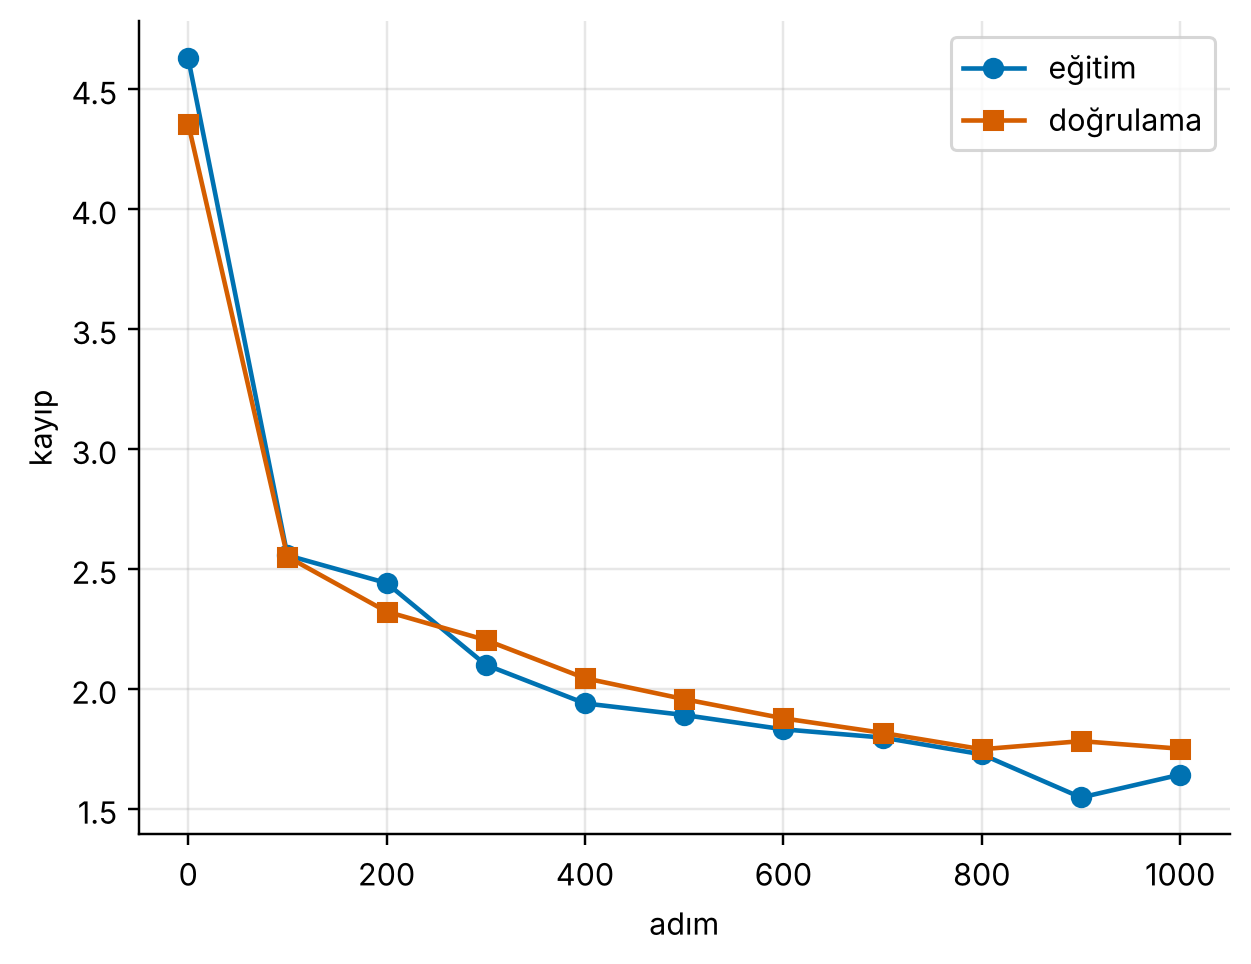

In [23]:
opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
adimlar, egt, dgr = [], [], []
for adim in range(1001):
    x, y = batch_al()
    _, kayip = model(x, y)       # 1) ileri yayılım
    opt.zero_grad()
    kayip.backward()             # 2) geri yayılım
    opt.step()                   # 3) güncelle
    if adim % 100 == 0:
        adimlar.append(adim); egt.append(kayip.item())
        dgr.append(dogr_kaybi(model))
print("eğitim   :", round(egt[0], 2), "→", round(egt[-1], 2))
print("doğrulama:", round(dgr[0], 2), "→", round(dgr[-1], 2))
plt.plot(adimlar, egt, "o-", label="eğitim")
plt.plot(adimlar, dgr, "s-", label="doğrulama")
plt.xlabel("adım"); plt.ylabel("kayıp")
plt.legend(); plt.show()

## P10. Eğitimden önce ve sonra

In [24]:
torch.manual_seed(0)
sonra = uret(model, "Yapay zekâ ", 260)
print("EĞİTİMDEN ÖNCE:");  print(textwrap.fill(once[:160], 80))
print("\nEĞİTİMDEN SONRA:"); print(textwrap.fill(sonra, 80))

EĞİTİMDEN ÖNCE:
Yapay zekâ jüİYE p7IDNYyA/GşMC0;MJogP-J0JtİtaXU2FotJ;aqylşwZ0ğ-"-u-8Öpk,UMk33İ
m? âA0;Y0(P49FÜG:'ö-VJO(s0"?1:WığfğÜW.dwTİ5ğs1aşL(Adh'")WL7BdGskdR
BsJ7mOMo'Htuba

EĞİTİMDEN SONRA:
Yapay zekâ zamal sayısayılır: Hiştenart kazalan antımasal (Aşağres- Geki öğren
mearlen katsayon örnekleri medronur verisinde ağırlıkla) nük paramama
(metorutuna seti sok öğrenmeye değili hesaple L1 kattalarılır. Gerarasıl
doğrusal model Sınıf eğitiliklerir. Tecest komel


## P11. Sıcaklık: aynı model, farklı cesaret

In [25]:
for T in [0.5, 1.0, 1.5]:
    torch.manual_seed(1)
    yazi = uret(model, "Model ", 140, sicaklik=T)
    print(f"T = {T}:", textwrap.fill(yazi, 78, subsequent_indent=" " * 8), "\n")

T = 0.5: Model öğreniler ve Jogram ağlarak katmanın olarak serinin birleştirir.
        Aşağıdaki sonun ilişlem olarak bir sineri kullanılır. Aşağın olarak
        öğrenme 



T = 1.0: Model öğrenileştirerir. Bu bir ağırlıklıklarda büyük donuyu ile- tüm öğrenit
        semeleri, ilişken ile olda proboro? Test ilerin fırkla kategoristel e 



T = 1.5: Model öğrenileştir: Mrjide Sx Guçsası projunun bültemedniy- w0 den 0 öğrenit
        som Şeki, 0/iki, Gio) olda prhise aBT)" 12'den bu saq6x mı?25ışma; WG 



## P12. Eğitilmiş modelin dikkat haritası
Son bloktaki dört başın her karakterin hangi önceki karakterlere baktığını çizelim.

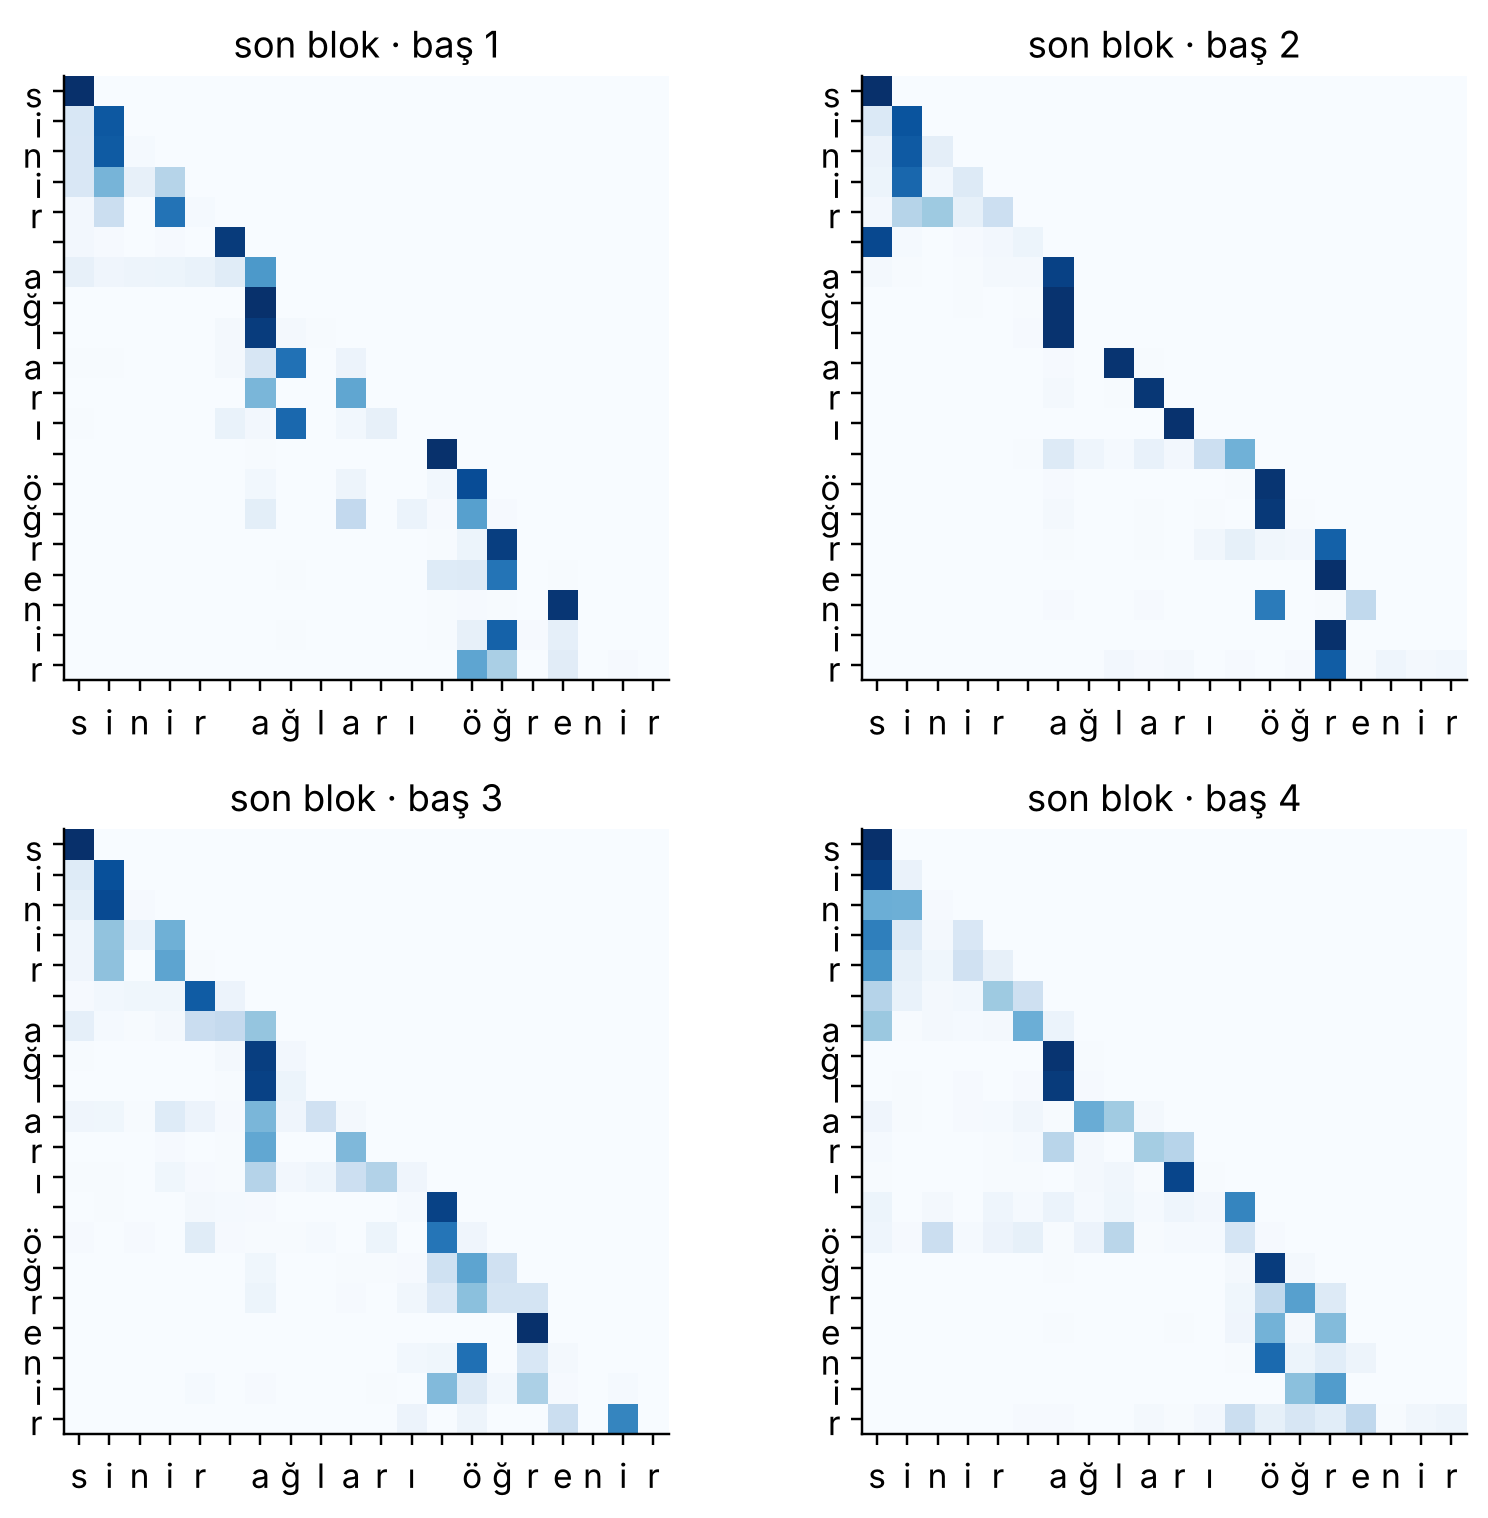

In [26]:
cumle = "sinir ağları öğrenir"
harf = list(cumle)
x = torch.tensor([kodla(cumle)])
model.eval(); model(x); model.train()
son = model.bloklar[-1].dikkat.baslar
fig, eks = plt.subplots(2, 2,
                        figsize=(7.5, 7))
for i, (ax, b) in enumerate(
        zip(eks.flat, son)):
    ax.imshow(b.agirlik[0].detach(),
              cmap="Blues")
    ks = range(len(harf))
    ax.set_xticks(ks, harf, fontsize=11)
    ax.set_yticks(ks, harf, fontsize=11)
    ax.set_title(f"son blok · baş {i + 1}")
    ax.grid(False)
plt.tight_layout(); plt.show()